**MAESTRÍA EN INTELIGENCIA ARTIFICIAL APLICADA**  
**Actividad | Dataset - Notebook | Individual**

**Dataset:** `Bank_Personal_Loan_Modelling.csv` (Kaggle)


**Nombre:** José Manuel Martínez Romero  
**Matrícula:** A01797899


# Índice

1. **Carga y descripción del dataset**
   - 1.1 Descripción de variables
   - 1.2 Carga y dimensiones
   - 1.3 Estructura y tipos de datos
   - 1.4 Estadísticas descriptivas iniciales

2. **Limpieza y calidad de los datos**
   - 2.1 Valores faltantes
   - 2.2 Valores inválidos e inconsistentes
   - 2.3 Validación de variables binarias
   - 2.4 Duplicados
   - 2.5 Corrección de tipos
   - 2.6 Identificación y tratamiento de outliers

3. **Análisis exploratorio de datos (EDA)**
   - 3.1 Estadísticas descriptivas de variables numéricas
   - 3.2 Histogramas y KDE
   - 3.3 Boxplots
   - 3.4 Estadísticas descriptivas de variables categóricas
   - 3.5 Gráficos de barras
   - 3.6 Relaciones entre variables
     - 3.6.1 Scatterplot Income vs CCAvg
     - 3.6.2 Heatmap de correlaciones
   - 3.7 Relación con la variable objetivo Personal Loan
     - 3.7.1 Variables numéricas vs. target
     - 3.7.2 Variables categóricas vs. target

4. **Modelo baseline**
   - 4.1 Definición del problema y selección del modelo
   - 4.2 Preparación de X e y
   - 4.3 División entrenamiento/prueba
   - 4.4 Escalado y entrenamiento de Regresión Logística
   - 4.5 Generación de predicciones

5. **Evaluación del modelo baseline**
   - 5.1 Métricas de desempeño
   - 5.2 Matriz de confusión
   - 5.3 Curva ROC y ROC-AUC
   - 5.4 Interpretación de resultados

6. **Registro del experimento en MLflow**
   - 6.1 Preparación del servidor de MLflow
   - 6.2 Configuración del experimento
   - 6.3 Registro de parámetros, métricas y artefactos
   - 6.4 Verificación del run
   - 6.5 Evidencia de la interfaz de MLflow

7. **Reflexión final sobre MLOps**


In [1]:
import sys
print(sys.executable)

/Users/josemtzromero01/Documents/Maestria-MNA/MLOps/hello-world-mlflow/mlops/bin/python3.13


In [2]:
# Importar las bibliotecas necesarias
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns


# 1. Carga y descripción del dataset


## 1.1 Descripción de variables

El archivo `Bank_Personal_Loan_Modelling.csv` contiene información demográfica,
financiera y de productos bancarios de clientes. La variable objetivo es
`Personal Loan`, que indica si el cliente aceptó (1) o no (0) un préstamo personal.

Variables:

- **ID:** identificador único del cliente.
- **Age:** edad del cliente en años.
- **Experience:** años de experiencia laboral.
- **Income:** ingreso anual, en miles de dólares.
- **ZIP Code:** código postal.
- **Family:** número de integrantes de la familia.
- **CCAvg:** gasto mensual promedio con tarjeta de crédito, en miles de dólares.
- **Education:** nivel educativo (1 = graduado, 2 = universitario, 3 = posgrado).
- **Mortgage:** monto de hipoteca, en miles de dólares.
- **Personal Loan:** variable objetivo (1 = aceptó, 0 = no aceptó).
- **Securities Account:** cuenta de valores (1 = sí, 0 = no).
- **CD Account:** certificado de depósito (1 = sí, 0 = no).
- **Online:** uso de banca en línea (1 = sí, 0 = no).
- **CreditCard:** titular de tarjeta de crédito (1 = sí, 0 = no).


## 1.2 Carga y dimensiones


In [3]:
# Carga del dataset descargado desde Kaggle
loan_df = pd.read_csv("Bank_Personal_Loan_Modelling.csv")

print(f"Registros: {loan_df.shape[0]}")
print(f"Columnas totales: {loan_df.shape[1]}")
display(loan_df.head())


Registros: 5000
Columnas totales: 14


,ID,Age,Experience,Income,ZIP Code,Family,CCAvg,Education,Mortgage,Personal Loan,Securities Account,CD Account,Online,CreditCard
0,1,25,1,49,91107,4,1.6,1,0,0,1,0,0,0
1,2,45,19,34,90089,3,1.5,1,0,0,1,0,0,0
2,3,39,15,11,94720,1,1.0,1,0,0,0,0,0,0
3,4,35,9,100,94112,1,2.7,2,0,0,0,0,0,0
4,5,35,8,45,91330,4,1.0,2,0,0,0,0,0,1


El dataset contiene **5,000 registros y 14 columnas**, incluyendo `ID`.
Para el análisis se utilizará `ID` como índice, por lo que quedan 13 variables de estudio.


In [4]:
# Verificar que ID sea único antes de utilizarlo como índice
print("IDs duplicados:", loan_df["ID"].duplicated().sum())
loan_df = loan_df.set_index("ID")


IDs duplicados: 0


## 1.3 Estructura y tipos de datos


In [5]:
loan_df.info()


<class 'pandas.DataFrame'>
RangeIndex: 5000 entries, 1 to 5000
Data columns (total 13 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   Age                 5000 non-null   int64  
 1   Experience          5000 non-null   int64  
 2   Income              5000 non-null   int64  
 3   ZIP Code            5000 non-null   int64  
 4   Family              5000 non-null   int64  
 5   CCAvg               5000 non-null   float64
 6   Education           5000 non-null   int64  
 7   Mortgage            5000 non-null   int64  
 8   Personal Loan       5000 non-null   int64  
 9   Securities Account  5000 non-null   int64  
 10  CD Account          5000 non-null   int64  
 11  Online              5000 non-null   int64  
 12  CreditCard          5000 non-null   int64  
dtypes: float64(1), int64(12)
memory usage: 507.9 KB


Inicialmente, pandas interpreta las 13 variables de análisis como numéricas
(12 enteras y una de punto flotante). Sin embargo, algunas columnas codificadas
con números representan categorías y se corregirán posteriormente de acuerdo con
su naturaleza estadística.


## 1.4 Estadísticas descriptivas iniciales


In [6]:
loan_df.describe().T


,count,mean,std,min,25%,50%,75%,max
Age,5000.0,45.338400,11.463166,23.0,35.0,45.0,55.0,67.0
Experience,5000.0,20.104600,11.467954,-3.0,10.0,20.0,30.0,43.0
Income,5000.0,73.774200,46.033729,8.0,39.0,64.0,98.0,224.0
ZIP Code,5000.0,93152.503000,2121.852197,9307.0,91911.0,93437.0,94608.0,96651.0
Family,5000.0,2.396400,1.147663,1.0,1.0,2.0,3.0,4.0
CCAvg,5000.0,1.937938,1.747659,0.0,0.7,1.5,2.5,10.0
Education,5000.0,1.881000,0.839869,1.0,1.0,2.0,3.0,3.0
Mortgage,5000.0,56.498800,101.713802,0.0,0.0,0.0,101.0,635.0
Personal Loan,5000.0,0.096000,0.294621,0.0,0.0,0.0,0.0,1.0
Securities Account,5000.0,0.104400,0.305809,0.0,0.0,0.0,0.0,1.0


Las estadísticas iniciales permiten identificar rangos y posibles inconsistencias.
En particular, `Experience` presenta valores negativos, lo cual no es coherente
con el significado de años de experiencia laboral y se revisará en la etapa de limpieza.


# 2. Limpieza y calidad de los datos


## 2.1 Valores faltantes

Se verifica de manera explícita la existencia de valores faltantes para decidir
si se requiere eliminación o imputación.


In [7]:
missing_values = loan_df.isnull().sum().to_frame(name="Valores faltantes")
display(missing_values)
print("Total de valores faltantes:", int(missing_values["Valores faltantes"].sum()))


,Valores faltantes
Age,0
Experience,0
Income,0
ZIP Code,0
Family,0
CCAvg,0
Education,0
Mortgage,0
Personal Loan,0
Securities Account,0


Total de valores faltantes: 0


**Decisión:** El dataset no contiene valores faltantes. Por lo tanto, no se
aplica eliminación ni imputación.


## 2.2 Valores inválidos e inconsistentes

Se revisan reglas básicas de validez basadas en la definición de las variables:
edad dentro de un rango plausible, experiencia no negativa, tamaño de familia
entre 1 y 4 y nivel educativo dentro de las categorías 1, 2 y 3.


In [8]:
# Resumen de valores inválidos o inconsistentes
quality_checks = pd.DataFrame({
    "Regla": [
        "Age fuera de 18-100",
        "Experience < 0",
        "Family fuera de 1-4",
        "Education fuera de 1-3"
    ],
    "Registros detectados": [
        ((loan_df["Age"] < 18) | (loan_df["Age"] > 100)).sum(),
        (loan_df["Experience"] < 0).sum(),
        (~loan_df["Family"].isin([1, 2, 3, 4])).sum(),
        (~loan_df["Education"].isin([1, 2, 3])).sum()
    ]
})

display(quality_checks)


,Regla,Registros detectados
0,Age fuera de 18-100,0
1,Experience < 0,52
2,Family fuera de 1-4,0
3,Education fuera de 1-3,0


En el archivo de Kaggle no se detectan edades fuera del rango revisado,
valores inválidos en `Family` ni categorías inválidas en `Education`.
El problema identificado corresponde a valores negativos en `Experience`,
los cuales no son interpretables como años de experiencia laboral.


In [9]:
# Tratamiento de valores negativos en Experience
initial_rows = loan_df.shape[0]
negative_experience = (loan_df["Experience"] < 0).sum()

loan_df = loan_df[loan_df["Experience"] >= 0].copy()

removed_pct = (negative_experience / initial_rows) * 100

print(f"Registros con Experience negativa eliminados: {negative_experience}")
print(f"Porcentaje eliminado: {removed_pct:.2f}%")
print(f"Registros restantes: {loan_df.shape[0]}")


Registros con Experience negativa eliminados: 52
Porcentaje eliminado: 1.04%
Registros restantes: 4948


**Decisión:** Se eliminan los registros con `Experience < 0` porque representan
un valor imposible para la variable. La cantidad afectada es pequeña respecto
al total del dataset, por lo que se prefiere eliminar estos registros antes que
inventar o imputar un valor de experiencia sin información adicional.


## 2.3 Validación de variables binarias


In [10]:
binary_columns = [
    "Personal Loan",
    "Securities Account",
    "CD Account",
    "Online",
    "CreditCard"
]

binary_validation = {
    col: sorted(loan_df[col].dropna().unique().tolist())
    for col in binary_columns
}

binary_validation


{'Personal Loan': [0, 1],
 'Securities Account': [0, 1],
 'CD Account': [0, 1],
 'Online': [0, 1],
 'CreditCard': [0, 1]}

**Decisión:** Todas las variables binarias ya utilizan de forma consistente los
valores `0` y `1`, por lo que no es necesario normalizar o reemplazar valores.
Posteriormente se convertirán a tipo categórico para reflejar su naturaleza estadística.


## 2.4 Duplicados


In [11]:
# ID ya fue validado como identificador único.
# Se buscan además registros duplicados considerando las variables de análisis.
duplicate_count = loan_df.duplicated().sum()

print("Registros duplicados:", duplicate_count)

if duplicate_count > 0:
    loan_df = loan_df.drop_duplicates().copy()
    print("Duplicados eliminados:", duplicate_count)
else:
    print("No fue necesario eliminar registros duplicados.")


Registros duplicados: 0
No fue necesario eliminar registros duplicados.


**Decisión:** No se identificaron registros duplicados en el dataset, por lo que
no se requiere tratamiento adicional.


## 2.5 Corrección de tipos


In [12]:
# ZIP Code es nominal, no una medida numérica.
loan_df["ZIP Code"] = loan_df["ZIP Code"].astype(str)

# Education es categórica ordinal.
education_order = [1, 2, 3]
loan_df["Education"] = pd.Categorical(
    loan_df["Education"],
    categories=education_order,
    ordered=True
)

# Variables binarias como categorías.
for col in binary_columns:
    loan_df[col] = loan_df[col].astype("category")

loan_df.info()


<class 'pandas.DataFrame'>
Index: 4948 entries, 1 to 5000
Data columns (total 13 columns):
 #   Column              Non-Null Count  Dtype   
---  ------              --------------  -----   
 0   Age                 4948 non-null   int64   
 1   Experience          4948 non-null   int64   
 2   Income              4948 non-null   int64   
 3   ZIP Code            4948 non-null   str     
 4   Family              4948 non-null   int64   
 5   CCAvg               4948 non-null   float64 
 6   Education           4948 non-null   category
 7   Mortgage            4948 non-null   int64   
 8   Personal Loan       4948 non-null   category
 9   Securities Account  4948 non-null   category
 10  CD Account          4948 non-null   category
 11  Online              4948 non-null   category
 12  CreditCard          4948 non-null   category
dtypes: category(6), float64(1), int64(5), str(1)
memory usage: 362.6 KB


**Decisión:** Aunque `ZIP Code`, `Education` y las variables binarias se almacenan
con números, no representan magnitudes continuas. Se ajustan sus tipos para que el
EDA trate correctamente la naturaleza nominal, ordinal y binaria de estas variables.


In [13]:
# Separación de variables según su naturaleza después de corregir tipos
num_cols = loan_df.select_dtypes(include=["int64", "float64"]).columns.tolist()
cat_cols = loan_df.select_dtypes(include=["object", "category"]).columns.tolist()

print("Variables numéricas:", num_cols)
print("Variables categóricas:", cat_cols)


Variables numéricas: ['Age', 'Experience', 'Income', 'Family', 'CCAvg', 'Mortgage']
Variables categóricas: ['ZIP Code', 'Education', 'Personal Loan', 'Securities Account', 'CD Account', 'Online', 'CreditCard']


/var/folders/fh/3dfvglsn269_4sx370gclvbr0000gn/T/ipykernel_19140/1747426755.py:3: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  cat_cols = loan_df.select_dtypes(include=["object", "category"]).columns.tolist()


## 2.6 Identificación y tratamiento de outliers

Se aplica el criterio del rango intercuartílico (IQR) para identificar posibles
valores atípicos en las variables numéricas. Un outlier estadístico no se considera
automáticamente un error; también se evalúa su plausibilidad según el significado
de la variable.


In [14]:
outlier_summary = []

for col in num_cols:
    q1 = loan_df[col].quantile(0.25)
    q3 = loan_df[col].quantile(0.75)
    iqr = q3 - q1

    lower_bound = q1 - 1.5 * iqr
    upper_bound = q3 + 1.5 * iqr

    outlier_count = (
        (loan_df[col] < lower_bound) |
        (loan_df[col] > upper_bound)
    ).sum()

    outlier_summary.append({
        "Variable": col,
        "Límite inferior": round(lower_bound, 2),
        "Límite superior": round(upper_bound, 2),
        "Posibles outliers": int(outlier_count)
    })

outlier_df = pd.DataFrame(outlier_summary)
display(outlier_df)


,Variable,Límite inferior,Límite superior,Posibles outliers
0,Age,7.50,83.50,0
1,Experience,-18.12,58.88,0
2,Income,-49.50,186.50,96
3,Family,-2.00,6.00,0
4,CCAvg,-2.15,5.45,296
5,Mortgage,-151.50,252.50,288


**Decisión:** El criterio IQR identifica valores extremos principalmente en
`Income`, `CCAvg` y `Mortgage`. Estos valores se conservan porque representan
cantidades financieras plausibles dentro del contexto del dataset y no existe
evidencia de que sean errores de captura. De esta forma se distingue entre un
valor estadísticamente atípico y un valor inválido, como sí ocurre con una
experiencia laboral negativa.


# 3. Análisis exploratorio de datos (EDA)


## 3.1 Estadísticas descriptivas de variables numéricas


In [15]:
numeric_stats = loan_df[num_cols].describe().T
display(numeric_stats)


,count,mean,std,min,25%,50%,75%,max
Age,4948.0,45.557195,11.320735,24.0,36.00,46.0,55.0,67.0
Experience,4948.0,20.331043,11.311973,0.0,10.75,20.0,30.0,43.0
Income,4948.0,73.814470,46.112596,8.0,39.00,64.0,98.0,224.0
Family,4948.0,2.391471,1.148444,1.0,1.00,2.0,3.0,4.0
CCAvg,4948.0,1.935926,1.747694,0.0,0.70,1.5,2.6,10.0
Mortgage,4948.0,56.634398,101.828885,0.0,0.00,0.0,101.0,635.0


Las estadísticas descriptivas permiten comparar tendencia central, dispersión y
rangos de las variables numéricas después de la limpieza. Esto complementa las
visualizaciones de distribución que se presentan a continuación.


## 3.2 Histogramas y KDE


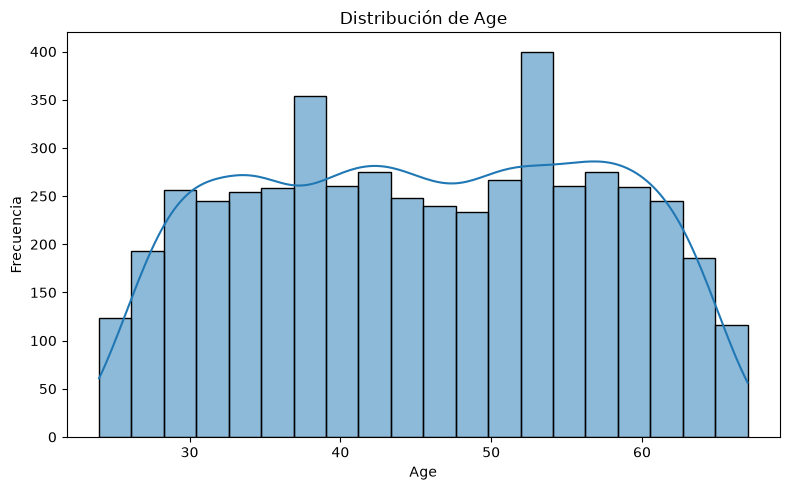

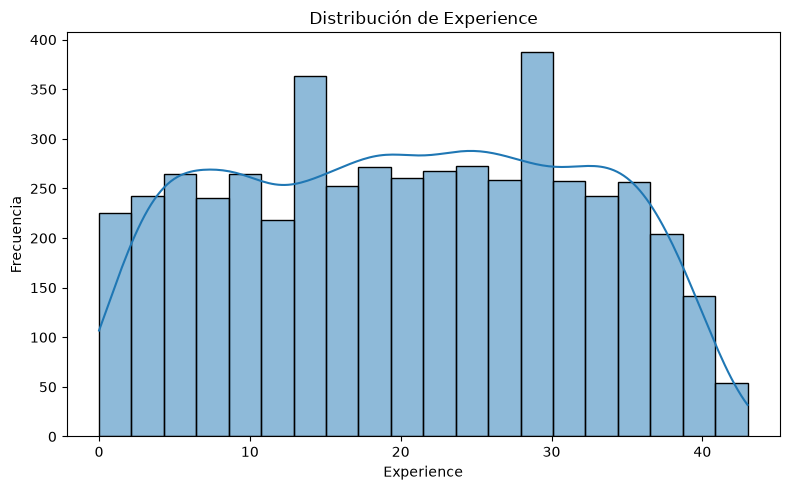

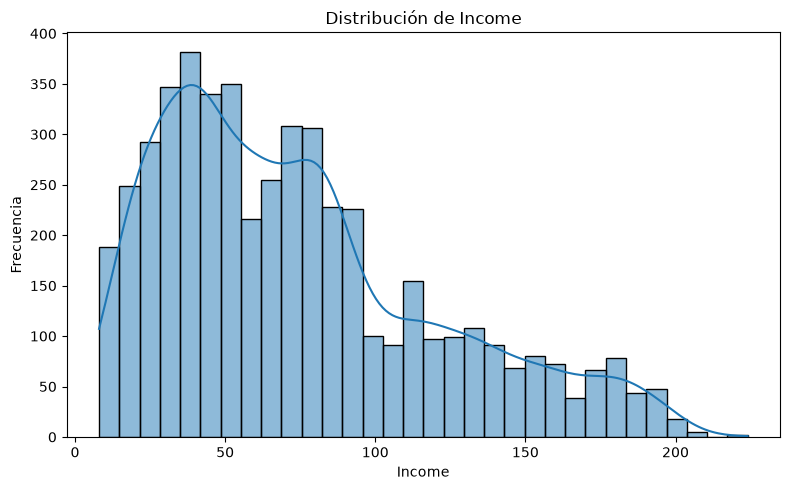

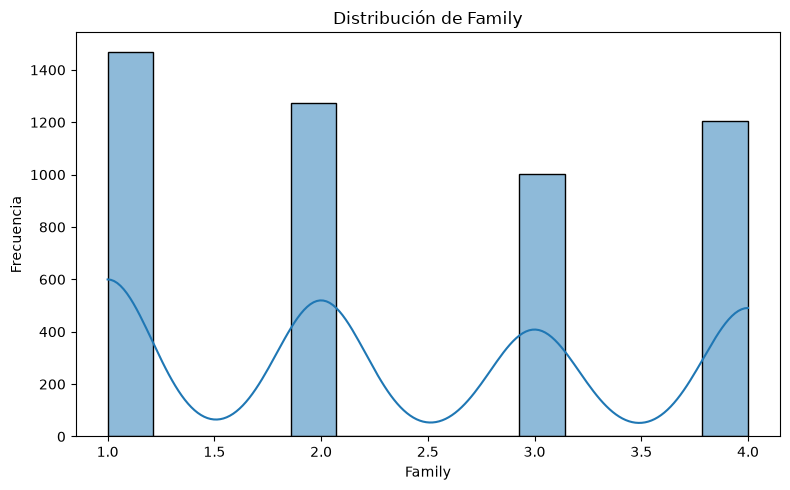

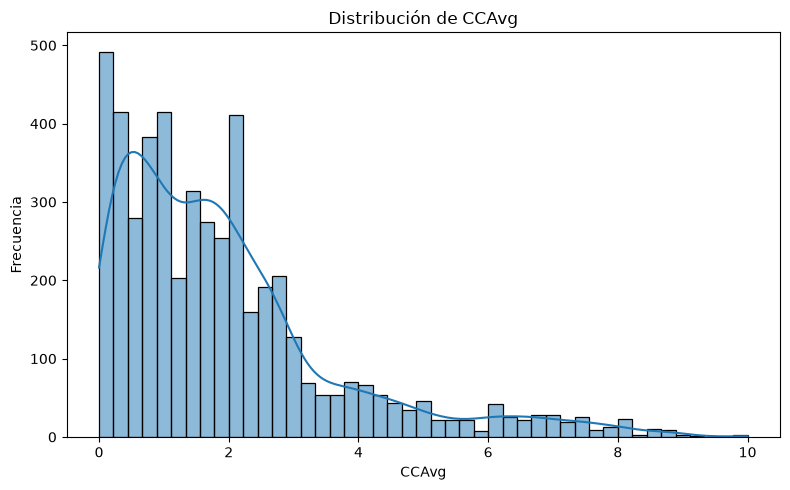

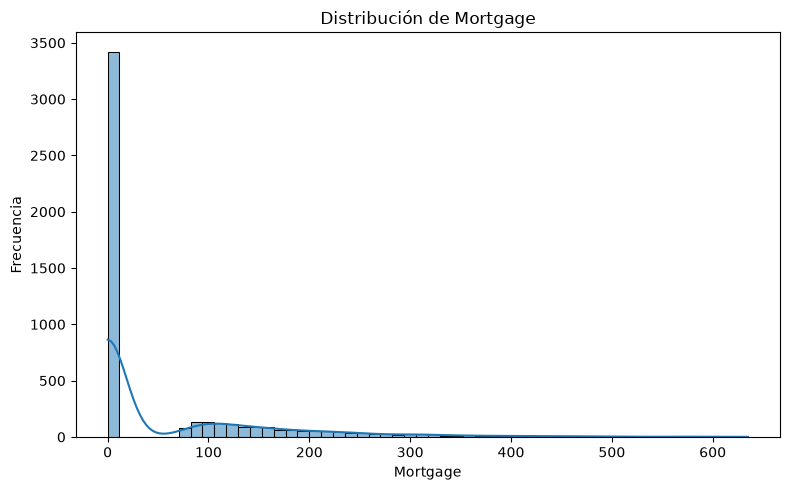

In [16]:
for col in num_cols:
    plt.figure(figsize=(8, 5))
    sns.histplot(data=loan_df, x=col, kde=True)
    plt.title(f"Distribución de {col}")
    plt.xlabel(col)
    plt.ylabel("Frecuencia")
    plt.tight_layout()
    plt.show()


Los histogramas y las curvas KDE muestran que algunas variables financieras,
especialmente `Income`, `CCAvg` y `Mortgage`, no presentan distribuciones
simétricas. Esto es consistente con la presencia de valores altos que fueron
identificados en la revisión de outliers.


## 3.3 Boxplots


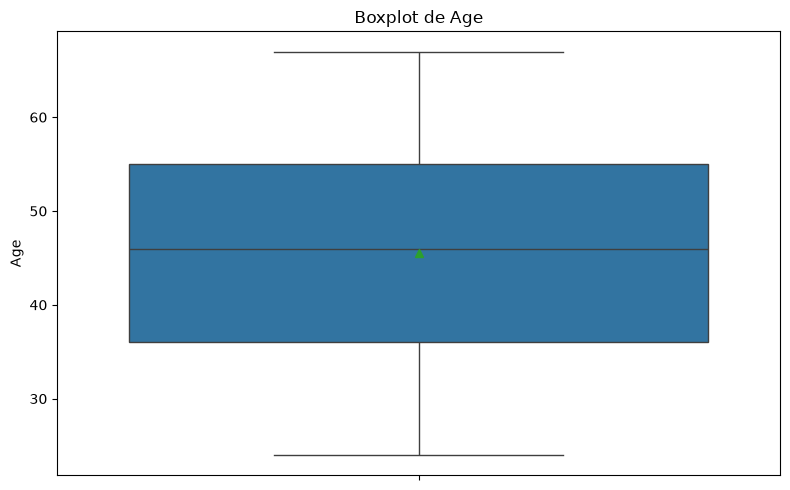

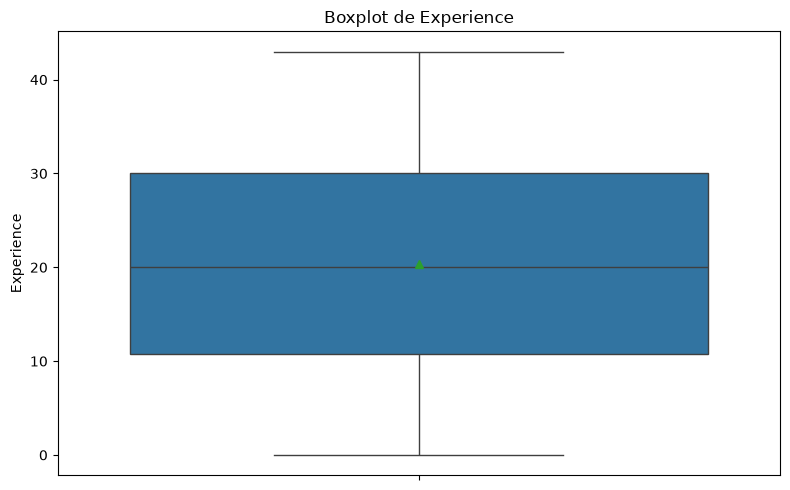

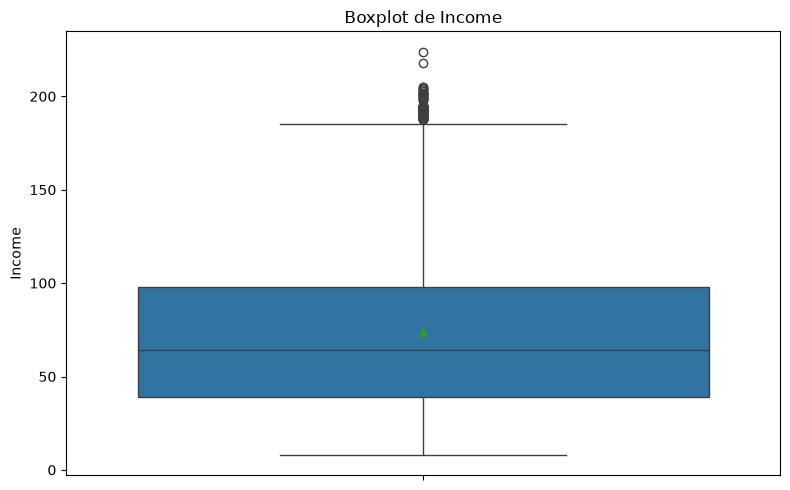

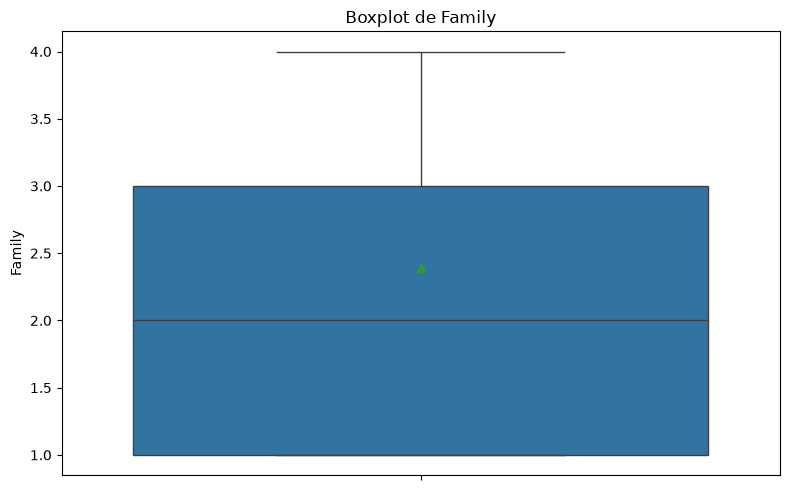

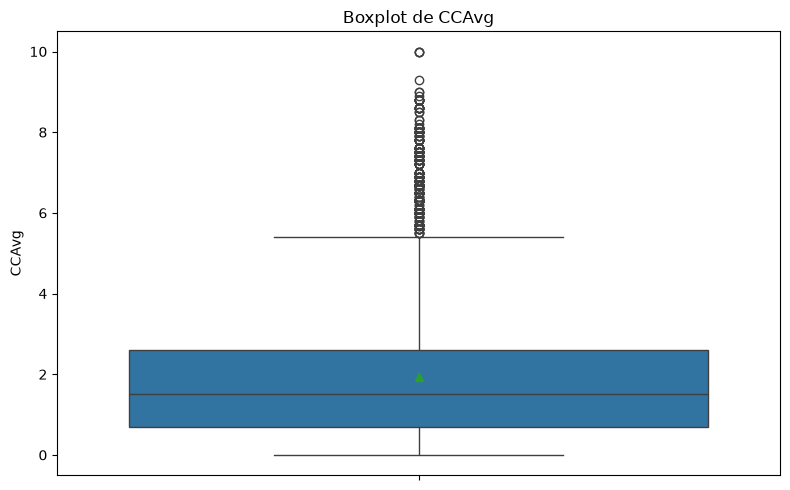

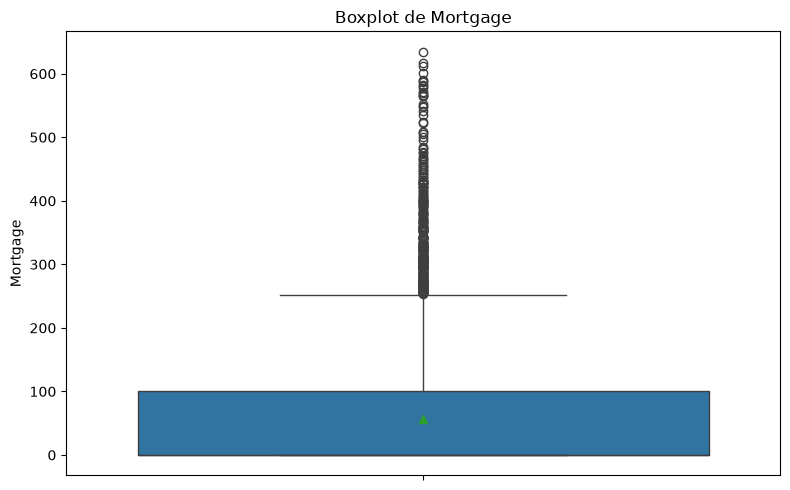

In [17]:
for col in num_cols:
    plt.figure(figsize=(8, 5))
    sns.boxplot(y=loan_df[col], showmeans=True)
    plt.title(f"Boxplot de {col}")
    plt.ylabel(col)
    plt.tight_layout()
    plt.show()


Los boxplots permiten visualizar la dispersión y los valores extremos. La presencia
de puntos fuera de los bigotes en variables financieras se interpreta junto con el
análisis IQR, por lo que no se eliminan únicamente por su condición estadística de outlier.


## 3.4 Estadísticas descriptivas de variables categóricas


In [18]:
display(loan_df[cat_cols].describe())


,ZIP Code,Education,Personal Loan,Securities Account,CD Account,Online,CreditCard
count,4948,4948,4948,4948,4948,4948,4948
unique,467,3,2,2,2,2,2
top,94720,1,0,0,0,1,0
freq,164,2080,4468,4432,4646,2954,3493


## 3.5 Gráficos de barras


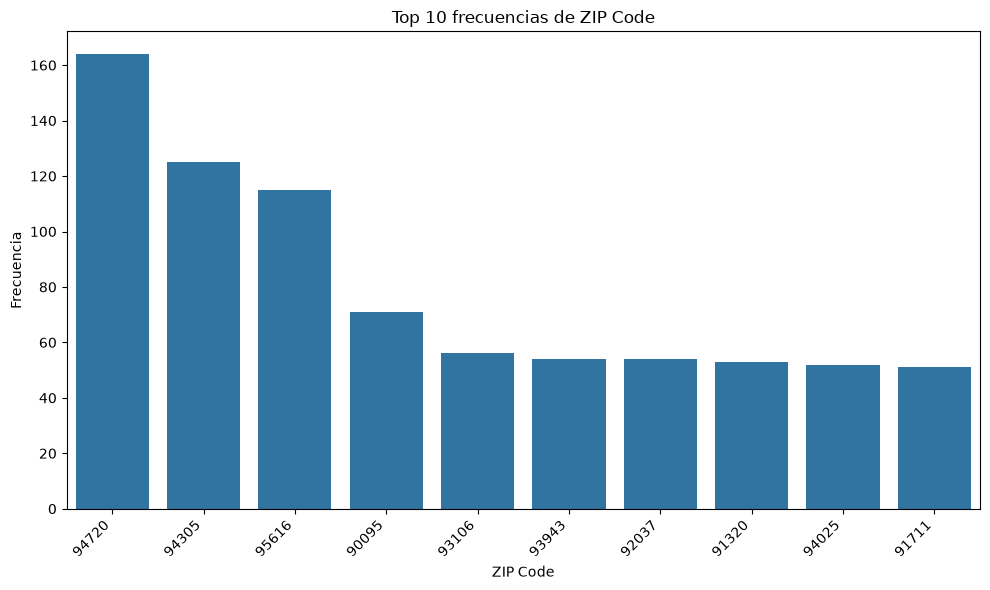

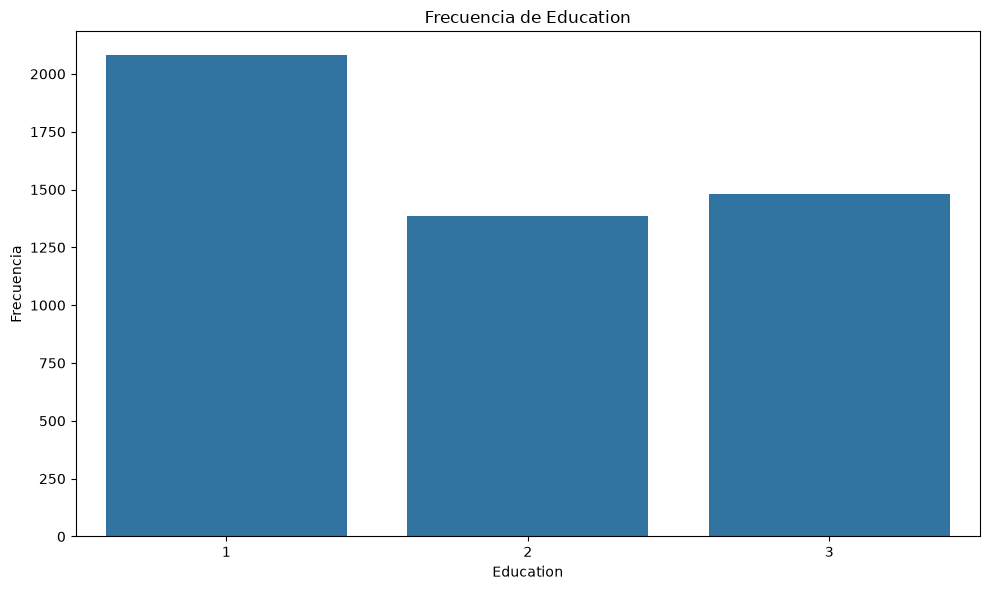

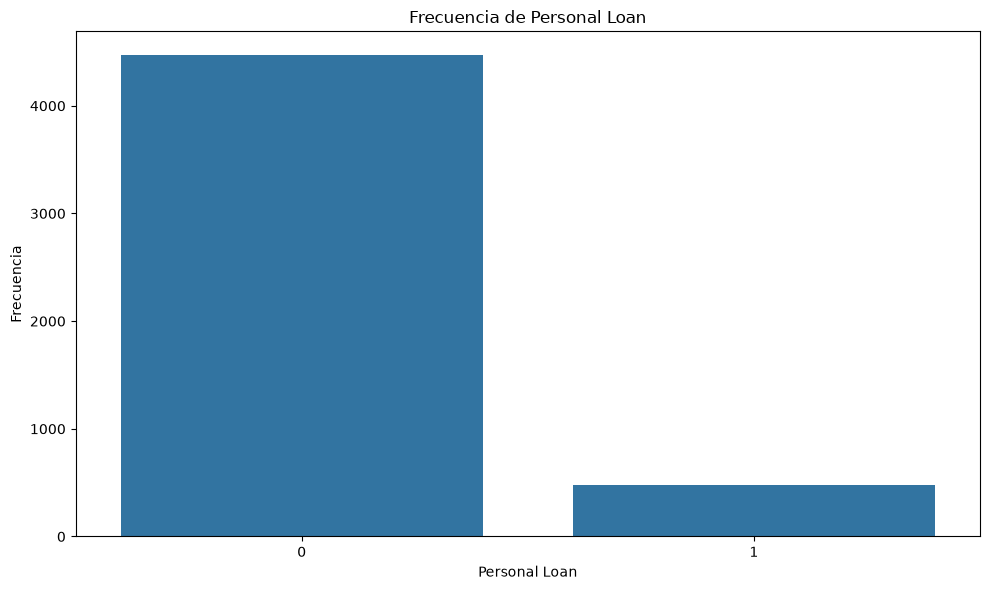

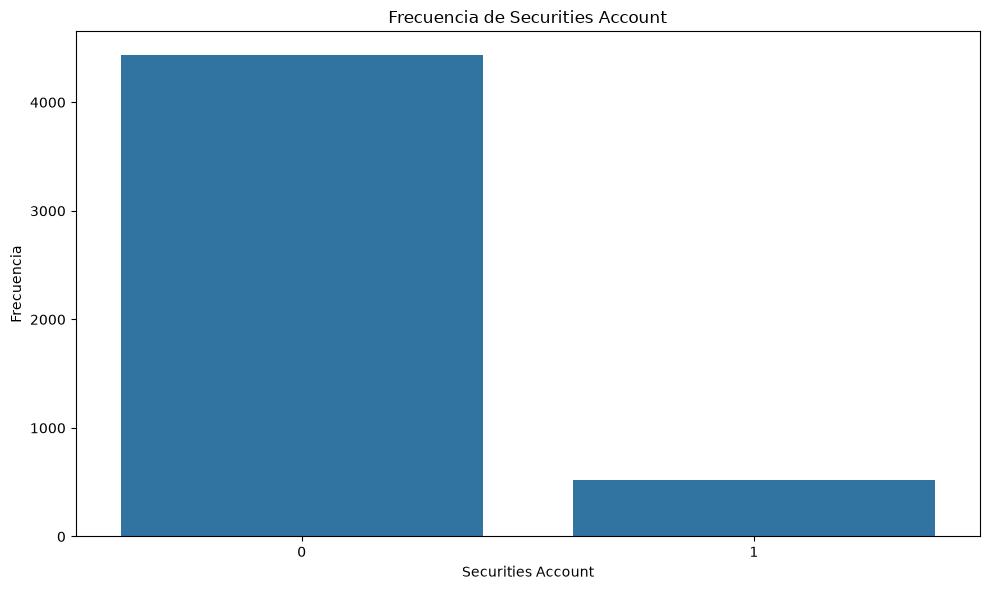

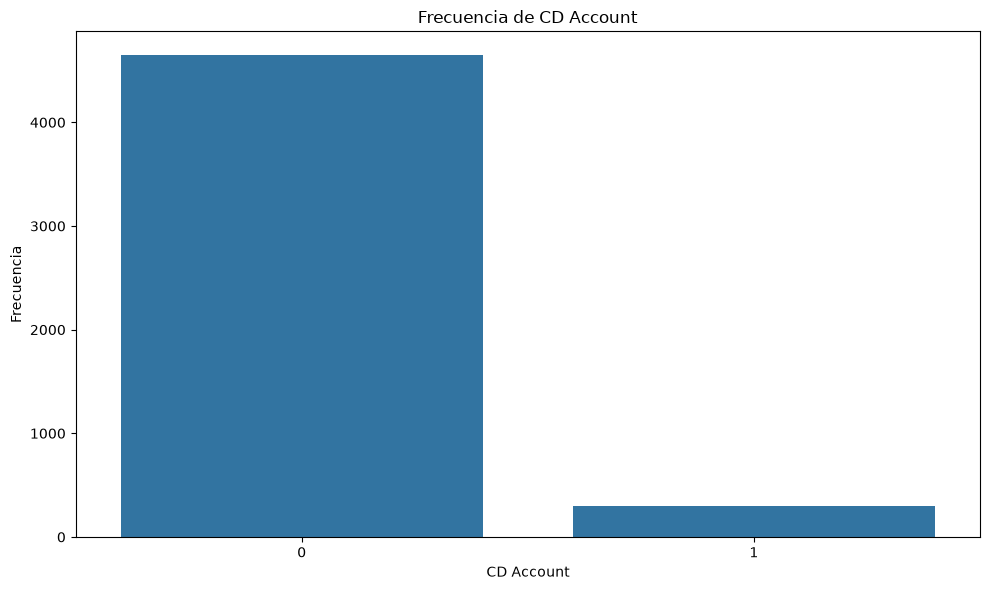

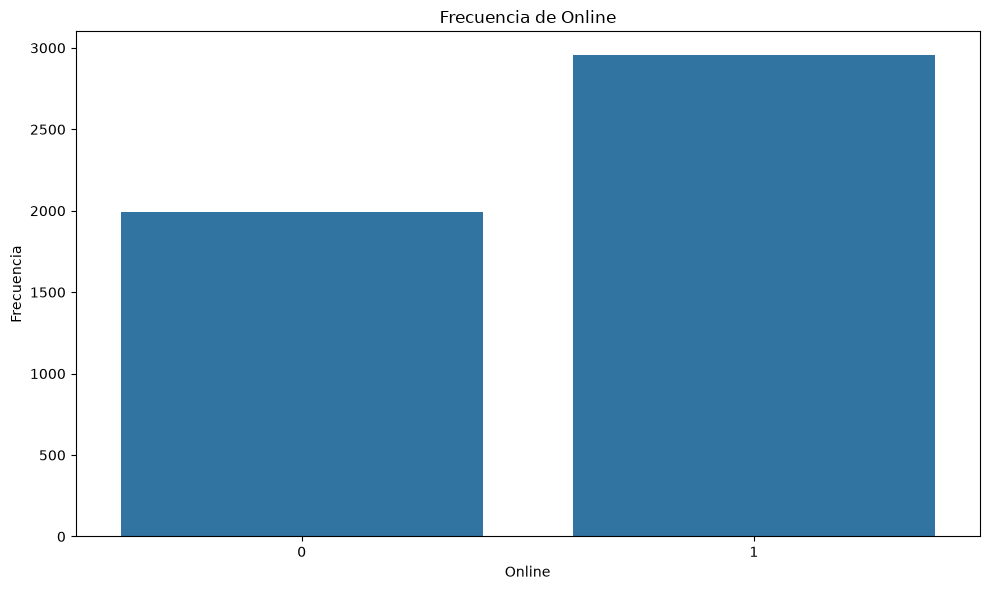

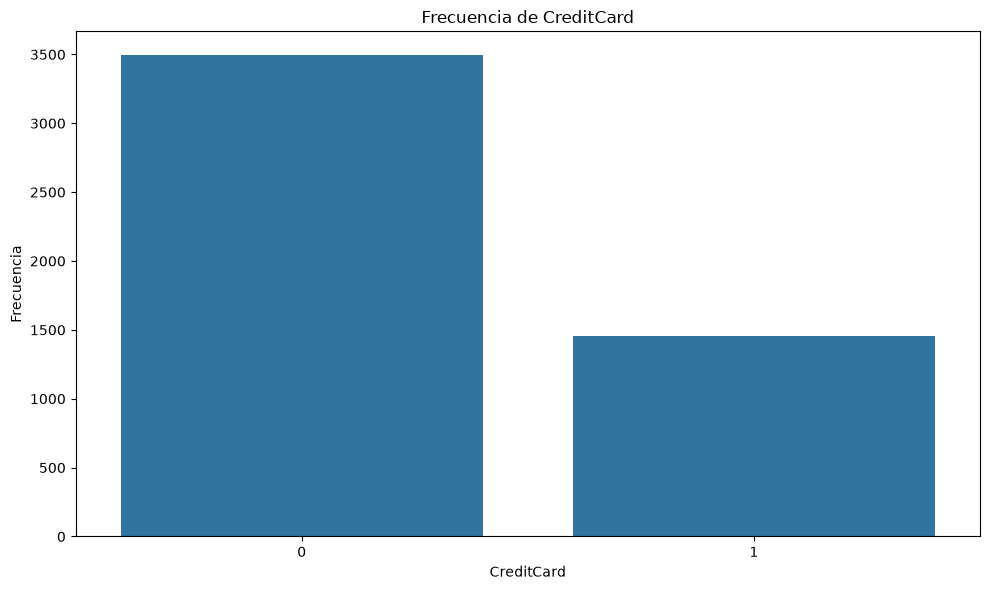

In [19]:
for col in cat_cols:
    plt.figure(figsize=(10, 6))

    if loan_df[col].nunique() > 10:
        top_categories = loan_df[col].value_counts().nlargest(10)
        sns.barplot(x=top_categories.index.astype(str), y=top_categories.values)
        plt.title(f"Top 10 frecuencias de {col}")
        plt.xticks(rotation=45, ha="right")
    else:
        sns.countplot(data=loan_df, x=col)
        plt.title(f"Frecuencia de {col}")

    plt.xlabel(col)
    plt.ylabel("Frecuencia")
    plt.tight_layout()
    plt.show()


Los gráficos de barras permiten observar la distribución de las variables categóricas.
Para `ZIP Code`, debido a su alta cardinalidad, se muestran únicamente las diez
categorías más frecuentes.


## 3.6 Relaciones entre variables


### 3.6.1 Scatterplot Income vs CCAvg


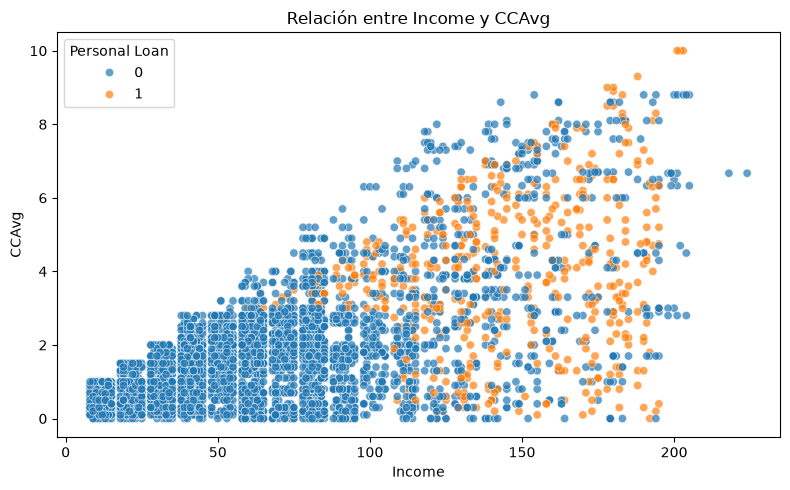

In [20]:
plt.figure(figsize=(8, 5))
sns.scatterplot(
    data=loan_df,
    x="Income",
    y="CCAvg",
    hue="Personal Loan",
    alpha=0.7
)
plt.title("Relación entre Income y CCAvg")
plt.xlabel("Income")
plt.ylabel("CCAvg")
plt.tight_layout()
plt.show()


El scatterplot permite observar una tendencia positiva entre `Income` y `CCAvg`:
en general, clientes con mayores ingresos tienden a presentar un gasto promedio
mayor con tarjeta de crédito. El color permite además observar cómo se distribuye
la variable objetivo en esta relación.


### 3.6.2 Heatmap de correlaciones


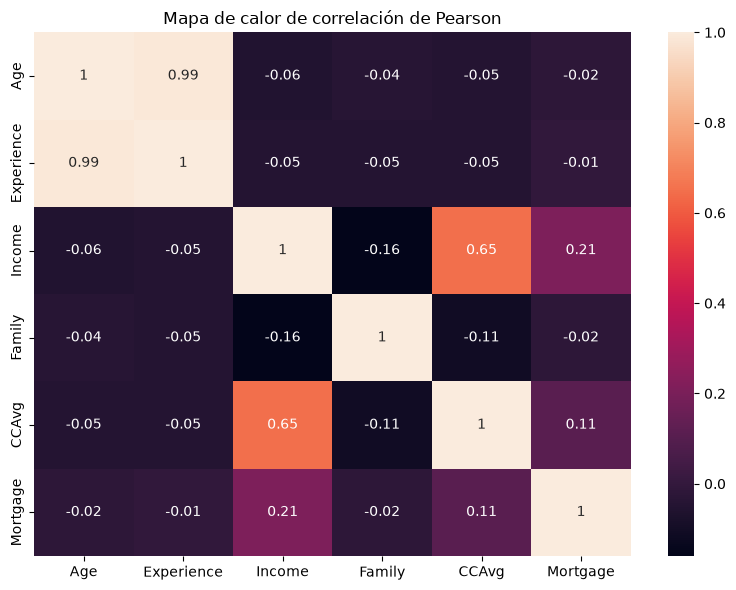

Correlación Income-CCAvg: 0.65


In [21]:
corr_matrix = loan_df[num_cols].corr(numeric_only=True)

plt.figure(figsize=(8, 6))
sns.heatmap(corr_matrix.round(2), annot=True, cmap=None)
plt.title("Mapa de calor de correlación de Pearson")
plt.tight_layout()
plt.show()

print(
    "Correlación Income-CCAvg:",
    round(corr_matrix.loc["Income", "CCAvg"], 2)
)


La correlación de Pearson entre `Income` y `CCAvg` es positiva y relativamente
alta, lo que coincide con la tendencia observada en el scatterplot. El heatmap
también permite identificar relaciones lineales entre el resto de las variables numéricas.


## 3.7 Relación con la variable objetivo Personal Loan


In [22]:
loan_distribution = loan_df["Personal Loan"].value_counts()
loan_percentage = loan_df["Personal Loan"].value_counts(normalize=True) * 100

target_summary = pd.DataFrame({
    "Registros": loan_distribution,
    "Porcentaje": loan_percentage.round(2)
})

display(target_summary)

,Registros,Porcentaje
Personal Loan,,
0,4468,90.3
1,480,9.7


La variable objetivo presenta un desbalance importante: aproximadamente 90.3% de los clientes no aceptaron el préstamo y 9.7% sí lo aceptaron. Este comportamiento deberá considerarse al seleccionar las métricas de evaluación del modelo baseline, ya que accuracy por sí sola podría resultar insuficiente.

### 3.7.1 Variables numéricas vs. target


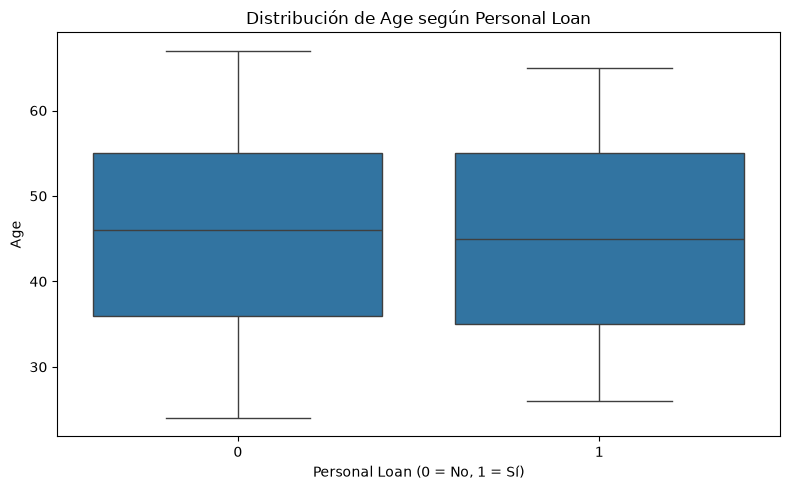

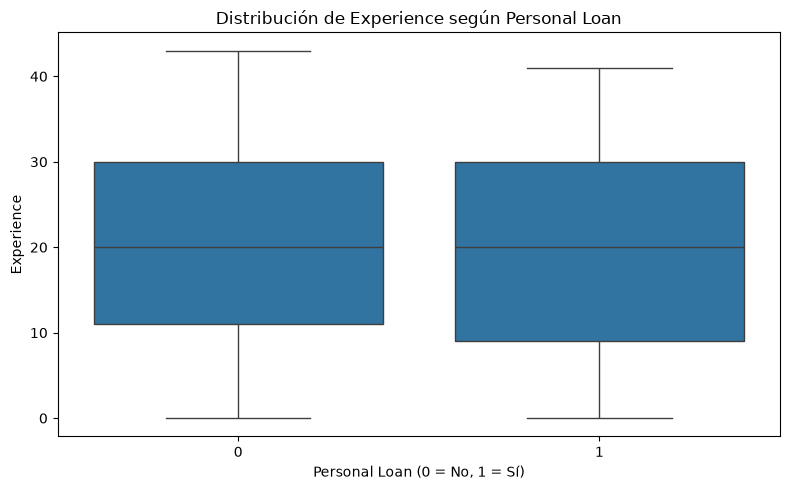

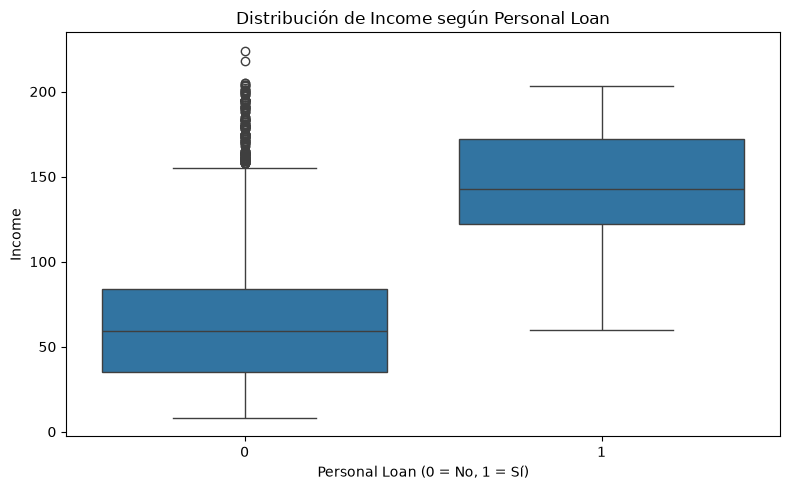

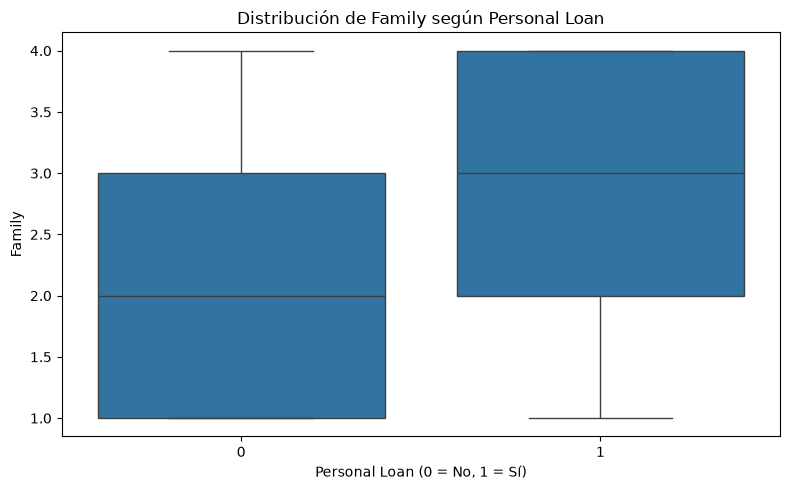

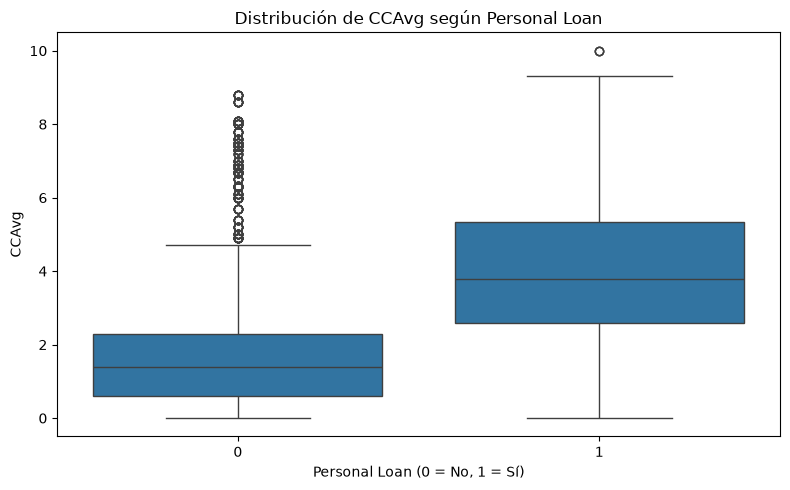

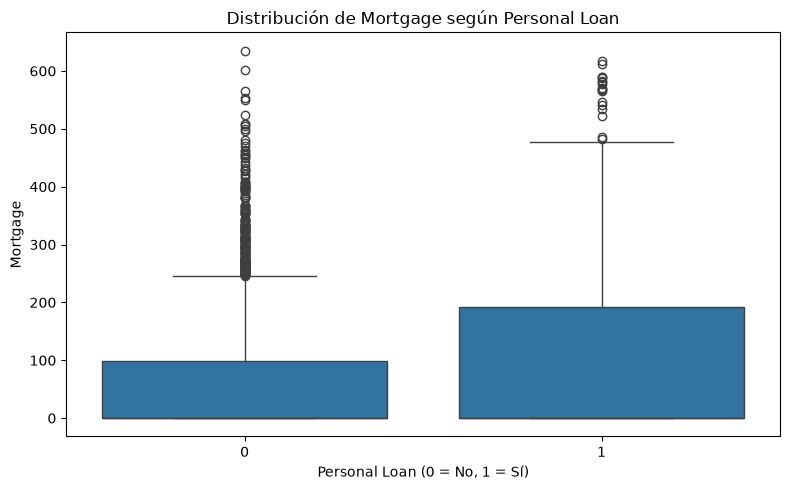

In [23]:
for col in num_cols:
    plt.figure(figsize=(8, 5))
    sns.boxplot(data=loan_df, x="Personal Loan", y=col)
    plt.title(f"Distribución de {col} según Personal Loan")
    plt.xlabel("Personal Loan (0 = No, 1 = Sí)")
    plt.ylabel(col)
    plt.tight_layout()
    plt.show()


**Hallazgos:** `Income` y `CCAvg` muestran diferencias visibles entre los clientes
que aceptaron y no aceptaron un préstamo personal. Esto sugiere que ambas variables
pueden aportar información relevante para el posterior modelo de clasificación.
`Mortgage` también presenta diferencias de distribución, aunque con mayor dispersión.


### 3.7.2 Variables categóricas vs. target


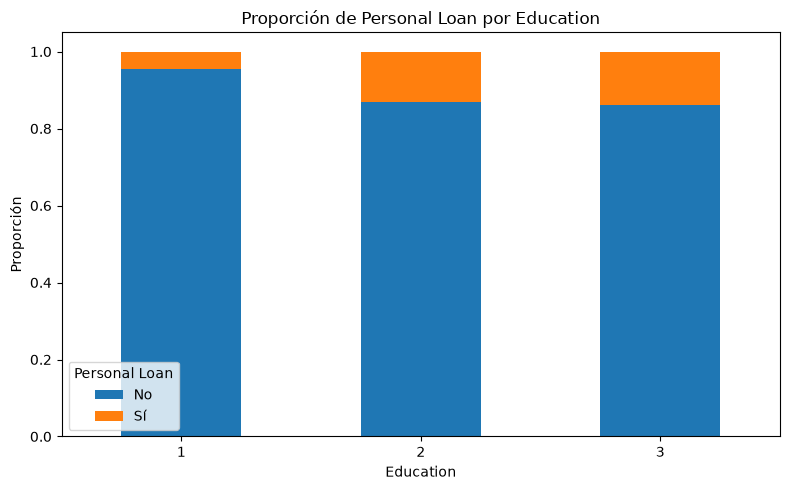

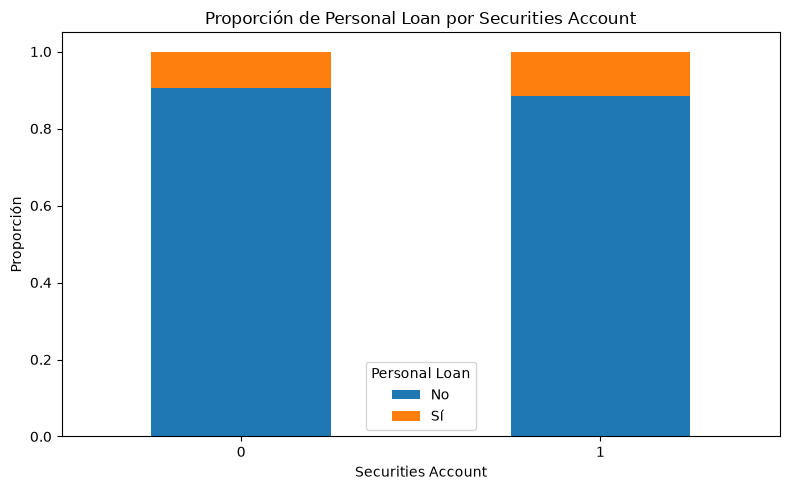

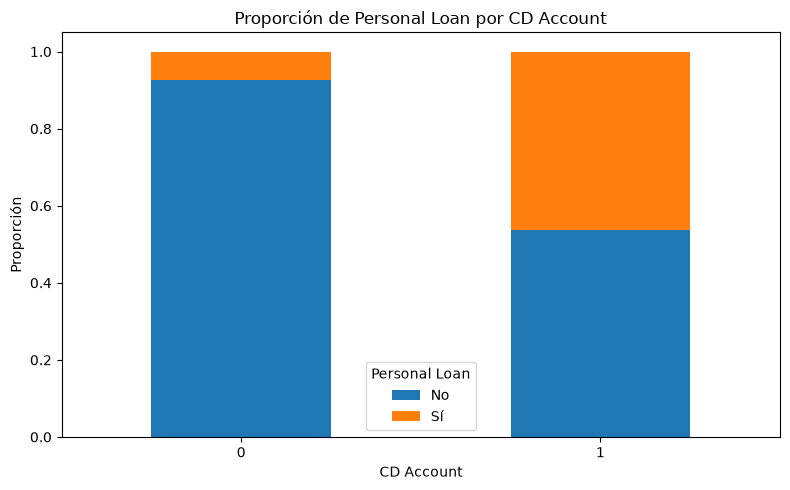

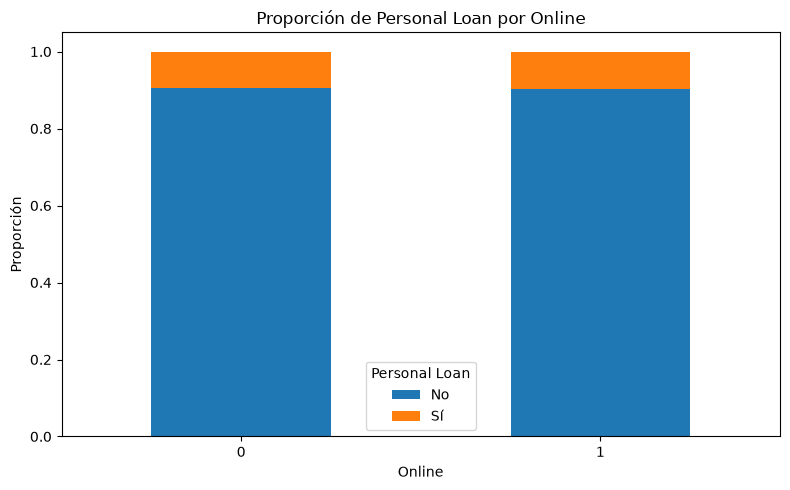

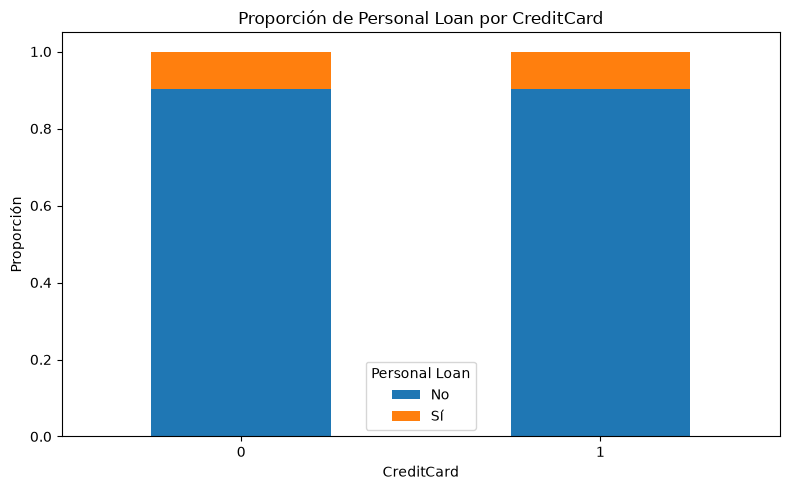

In [24]:
cat_cols_for_bivariate = [
    col for col in cat_cols
    if col not in ["ZIP Code", "Personal Loan"]
]

for col in cat_cols_for_bivariate:
    contingency_table = pd.crosstab(
        loan_df[col],
        loan_df["Personal Loan"],
        normalize="index"
    )

    contingency_table.plot(
        kind="bar",
        stacked=True,
        figsize=(8, 5)
    )

    plt.title(f"Proporción de Personal Loan por {col}")
    plt.xlabel(col)
    plt.ylabel("Proporción")
    plt.xticks(rotation=0)
    plt.legend(title="Personal Loan", labels=["No", "Sí"])
    plt.tight_layout()
    plt.show()


**Hallazgos:** `Education` y `CD Account` muestran diferencias claras en la
proporción de aceptación del préstamo personal entre categorías. En particular,
los clientes con `CD Account = 1` presentan una proporción de aceptación mayor.
Las diferencias para `Online`, `CreditCard` y `Securities Account` son menos
pronunciadas visualmente.

En conjunto, el EDA permite comprender la distribución de las variables y sus
relaciones, y deja el dataset preparado para la siguiente etapa: separación en
entrenamiento/prueba y construcción de un modelo baseline.


## 3.8 Conclusiones del EDA

El análisis exploratorio muestra que el dataset contiene principalmente clientes que no aceptaron el préstamo personal, por lo que existe un desbalance en la variable objetivo. Entre las variables numéricas, Income y CCAvg presentan diferencias claras entre los clientes que aceptaron y no aceptaron el préstamo. Además, ambas variables muestran una correlación positiva de aproximadamente 0.65. Entre las variables categóricas, Education y especialmente CD Account presentan diferencias relevantes en la proporción de aceptación. Los valores extremos identificados en Income, CCAvg y Mortgage se conservaron debido a que son financieramente plausibles. Después de la limpieza, el conjunto queda con 4,948 registros y está preparado para la etapa de modelado.

# 4. Modelo baseline

De acuerdo con el objetivo de la actividad, en esta sección se entrena un modelo
base sencillo y apropiado para el problema. La variable objetivo `Personal Loan`
es binaria (`0` = no aceptó el préstamo, `1` = sí aceptó), por lo que se trata de
un problema de **clasificación binaria**.

Como baseline se utiliza **Regresión Logística**, siguiendo el enfoque presentado
en el capítulo 4 de *Machine Learning Engineering with MLflow*, donde se emplea
`LogisticRegression` como un clasificador lineal de referencia y se realiza la
separación entrenamiento/prueba con `train_test_split` y `stratify`.

En esta etapa se entrena únicamente el baseline. El registro del experimento con
MLflow se realizará posteriormente en el Paso 6, de acuerdo con la secuencia de la
actividad.


## 4.1 Definición del problema y selección del modelo

La Regresión Logística es adecuada como punto de partida porque es un modelo
simple, interpretable y ampliamente utilizado para clasificación binaria. El
objetivo en esta actividad no es obtener el mejor modelo posible, sino establecer
un punto de referencia reproducible que posteriormente pueda evaluarse y registrarse
en MLflow.


In [25]:
# Librerías para el modelo baseline
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler


## 4.2 Preparación de las variables X e y

Se excluye `ZIP Code` del baseline porque es una variable nominal de alta
cardinalidad y su incorporación requeriría una codificación adicional que aumentaría
innecesariamente la complejidad del modelo base. `ID` ya se utiliza como índice y
tampoco forma parte de las variables predictoras.

Las variables ordinales y binarias se convierten temporalmente a valores numéricos
para que puedan ser utilizadas por Scikit-learn.


In [26]:
# Variables predictoras utilizadas por el baseline
feature_cols = [
    "Age",
    "Experience",
    "Income",
    "Family",
    "CCAvg",
    "Education",
    "Mortgage",
    "Securities Account",
    "CD Account",
    "Online",
    "CreditCard"
]

# X contiene las variables predictoras y y la variable objetivo.
# Algunas columnas son category en el EDA, por lo que se convierten a float/int
# únicamente para el entrenamiento del modelo.
X = loan_df[feature_cols].astype(float)
y = loan_df["Personal Loan"].astype(int)

print("Dimensiones de X:", X.shape)
print("Dimensiones de y:", y.shape)
display(X.head())


Dimensiones de X: (4948, 11)
Dimensiones de y: (4948,)


,Age,Experience,Income,Family,CCAvg,Education,Mortgage,Securities Account,CD Account,Online,CreditCard
ID,,,,,,,,,,,
1,25.0,1.0,49.0,4.0,1.6,1.0,0.0,1.0,0.0,0.0,0.0
2,45.0,19.0,34.0,3.0,1.5,1.0,0.0,1.0,0.0,0.0,0.0
3,39.0,15.0,11.0,1.0,1.0,1.0,0.0,0.0,0.0,0.0,0.0
4,35.0,9.0,100.0,1.0,2.7,2.0,0.0,0.0,0.0,0.0,0.0
5,35.0,8.0,45.0,4.0,1.0,2.0,0.0,0.0,0.0,0.0,1.0


## 4.3 División de los datos en entrenamiento y prueba

Siguiendo el enfoque del notebook de referencia del capítulo 4, se utiliza
`train_test_split` con `random_state=4284` y `stratify=y`. La estratificación es
especialmente importante en este dataset debido al desbalance de la variable
objetivo, ya que permite conservar aproximadamente la misma proporción de las
clases 0 y 1 en los conjuntos de entrenamiento y prueba.

Se reserva el 33% de los registros para prueba, siguiendo la proporción utilizada
en el ejemplo de Regresión Logística del capítulo.


In [27]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.33,
    random_state=4284,
    stratify=y
)

print("Registros de entrenamiento:", X_train.shape[0])
print("Registros de prueba:", X_test.shape[0])

split_summary = pd.DataFrame({
    "Train (%)": (y_train.value_counts(normalize=True).sort_index() * 100).round(2),
    "Test (%)": (y_test.value_counts(normalize=True).sort_index() * 100).round(2)
})

display(split_summary)


Registros de entrenamiento: 3315
Registros de prueba: 1633


,Train (%),Test (%)
Personal Loan,,
0,90.29,90.32
1,9.71,9.68


La tabla anterior permite comprobar que la estratificación conserva el desbalance
original de `Personal Loan` en ambos subconjuntos. De esta manera, el conjunto de
prueba mantiene una distribución representativa de la variable objetivo.


## 4.4 Escalado y entrenamiento de Regresión Logística

A diferencia del ejemplo del libro, este dataset contiene variables numéricas con
escalas muy distintas, como `Age`, `Income`, `CCAvg` y `Mortgage`. Por esta razón
se incorpora `StandardScaler` dentro de un `Pipeline` antes de la Regresión
Logística.

El uso del pipeline permite que el escalado se ajuste exclusivamente con los datos
de entrenamiento, evitando utilizar información del conjunto de prueba durante el
entrenamiento.


In [28]:
# Pipeline del baseline:
# 1) estandariza las variables
# 2) entrena el clasificador de Regresión Logística
baseline_model = Pipeline([
    ("scaler", StandardScaler()),
    (
        "logistic_regression",
        LogisticRegression(
            max_iter=1000,
            random_state=4284
        )
    )
])

baseline_model.fit(X_train, y_train)

print("Modelo baseline entrenado correctamente.")


Modelo baseline entrenado correctamente.


## 4.5 Generación de predicciones

Una vez entrenado el modelo se generan las predicciones sobre el conjunto de prueba.
La evaluación cuantitativa de estas predicciones se realizará en el **Paso 5**, donde
se calcularán métricas coherentes con el problema de clasificación y con el
desbalance observado en la variable objetivo.


In [29]:
# Predicciones del baseline sobre datos no vistos durante el entrenamiento
y_pred = baseline_model.predict(X_test)

print("Número de predicciones generadas:", len(y_pred))
print("Primeras 10 predicciones:", y_pred[:10])


Número de predicciones generadas: 1633
Primeras 10 predicciones: [0 0 0 0 1 0 0 0 0 0]


El modelo baseline queda entrenado y las predicciones sobre el conjunto de prueba
quedan disponibles en `y_pred`. Con esto se completa el Paso 4 y se deja preparado
el flujo para evaluar el desempeño del modelo en el Paso 5.


# 5. Evaluación del modelo baseline

La actividad solicita evaluar el modelo mediante al menos una métrica coherente
con el tipo de problema e interpretar el resultado de manera detallada.

Debido a que `Personal Loan` presenta un desbalance aproximado de 90% para la
clase 0 y 10% para la clase 1, no es conveniente evaluar el modelo únicamente
con `accuracy`. Por esta razón se reportan también `precision`, `recall`,
`F1-score` y `ROC-AUC`, además de la matriz de confusión.


## 5.1 Métricas de desempeño

Las métricas se calculan sobre el conjunto de prueba, es decir, sobre datos que
no fueron utilizados para entrenar el modelo.

- **Accuracy:** proporción total de predicciones correctas.
- **Precision:** de los casos predichos como clase positiva, qué proporción fue correcta.
- **Recall:** de los casos realmente positivos, qué proporción fue detectada por el modelo.
- **F1-score:** media armónica entre precision y recall.
- **ROC-AUC:** capacidad del modelo para distinguir entre ambas clases considerando
  diferentes umbrales de decisión.


In [30]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    confusion_matrix,
    classification_report,
    RocCurveDisplay
)

# Probabilidades de la clase positiva para ROC-AUC
y_proba = baseline_model.predict_proba(X_test)[:, 1]

# Cálculo de métricas
accuracy = accuracy_score(y_test, y_pred)
precision = precision_score(y_test, y_pred, zero_division=0)
recall = recall_score(y_test, y_pred, zero_division=0)
f1 = f1_score(y_test, y_pred, zero_division=0)
roc_auc = roc_auc_score(y_test, y_proba)

metrics_df = pd.DataFrame({
    "Métrica": ["Accuracy", "Precision", "Recall", "F1-score", "ROC-AUC"],
    "Valor": [accuracy, precision, recall, f1, roc_auc]
})

display(metrics_df.style.format({"Valor": "{:.4f}"}))

print("\nClassification report:")
print(classification_report(y_test, y_pred, digits=4, zero_division=0))


,Métrica,Valor
0,Accuracy,0.9528
1,Precision,0.8522
2,Recall,0.6203
3,F1-score,0.7179
4,ROC-AUC,0.9584



Classification report:
              precision    recall  f1-score   support

           0     0.9605    0.9885    0.9743      1475
           1     0.8522    0.6203    0.7179       158

    accuracy                         0.9528      1633
   macro avg     0.9063    0.8044    0.8461      1633
weighted avg     0.9500    0.9528    0.9495      1633



## 5.2 Matriz de confusión

La matriz de confusión permite observar cuántos casos fueron clasificados
correctamente e incorrectamente para cada clase. Esto es especialmente útil en
un problema desbalanceado porque permite identificar falsos positivos y falsos
negativos que podrían quedar ocultos si se observa únicamente el `accuracy`.


,Predicho 0,Predicho 1
Real 0,1458,17
Real 1,60,98


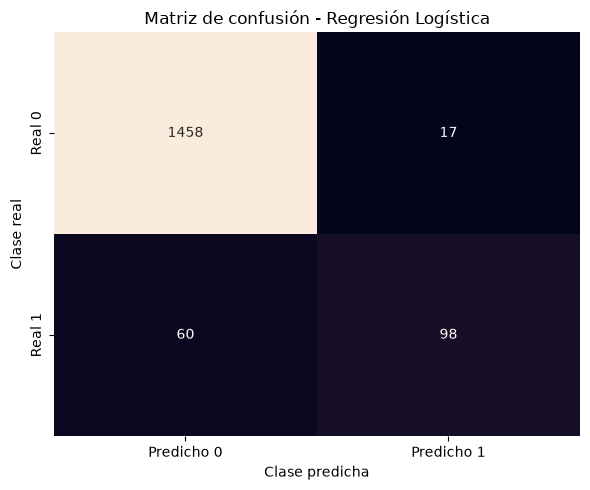

In [31]:
cm = confusion_matrix(y_test, y_pred)

cm_df = pd.DataFrame(
    cm,
    index=["Real 0", "Real 1"],
    columns=["Predicho 0", "Predicho 1"]
)

display(cm_df)

plt.figure(figsize=(6, 5))
sns.heatmap(
    cm_df,
    annot=True,
    fmt="d",
    cbar=False
)
plt.title("Matriz de confusión - Regresión Logística")
plt.xlabel("Clase predicha")
plt.ylabel("Clase real")
plt.tight_layout()
plt.show()


## 5.3 Curva ROC y ROC-AUC

La curva ROC muestra la relación entre la tasa de verdaderos positivos y la tasa
de falsos positivos a diferentes umbrales de clasificación. El área bajo la curva
(`ROC-AUC`) resume la capacidad general del modelo para separar ambas clases.


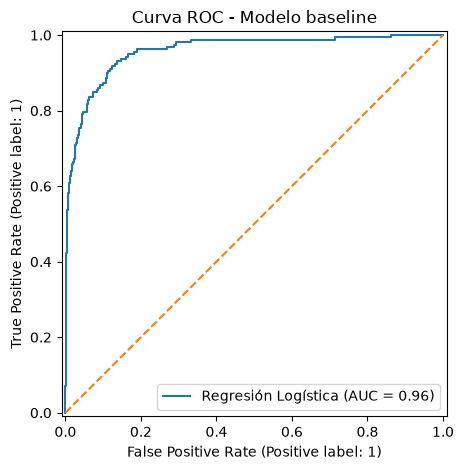

In [32]:
RocCurveDisplay.from_predictions(
    y_test,
    y_proba,
    name="Regresión Logística"
)

plt.plot([0, 1], [0, 1], linestyle="--")
plt.title("Curva ROC - Modelo baseline")
plt.tight_layout()
plt.show()


## 5.4 Interpretación de resultados

El modelo baseline de Regresión Logística obtuvo un **accuracy de 95.28%**, lo cual indica un buen desempeño global. Sin embargo, debido al desbalance de la variable objetivo, esta métrica debe analizarse junto con `precision`, `recall` y `F1-score`.

Para la clase positiva (`Personal Loan = 1`), el modelo alcanzó una **precision de 85.22%**, lo que significa que la mayoría de los clientes identificados por el modelo como aceptantes del préstamo fueron clasificados correctamente. El **recall fue de 62.03%**, por lo que el modelo detectó **98 de los 158 casos positivos**, mientras que **60 casos positivos fueron clasificados como negativos**. El **F1-score de 71.79%** resume el balance entre `precision` y `recall`.

El valor de **ROC-AUC = 95.84%** muestra una capacidad discriminativa muy alta para distinguir entre clientes que aceptan y no aceptan el préstamo al considerar distintos umbrales de clasificación. Este resultado es consistente con la forma de la curva ROC, que se mantiene claramente por encima de la diagonal correspondiente a un clasificador aleatorio.

El ROC-AUC alto y el recall de 62.03% no son contradictorios: el ROC-AUC evalúa la capacidad general del modelo para ordenar y separar las dos clases a través de distintos umbrales, mientras que el recall corresponde al desempeño obtenido con el umbral de decisión utilizado por el modelo. En conjunto, el baseline presenta un desempeño sólido, aunque existe oportunidad de mejorar la detección de la clase positiva y reducir los falsos negativos.


In [33]:
tn, fp, fn, tp = cm.ravel()

print("Resumen del modelo baseline")
print("-" * 35)
print(f"Accuracy : {accuracy:.4f}")
print(f"Precision: {precision:.4f}")
print(f"Recall   : {recall:.4f}")
print(f"F1-score : {f1:.4f}")
print(f"ROC-AUC  : {roc_auc:.4f}")
print()
print(f"Verdaderos negativos (TN): {tn}")
print(f"Falsos positivos (FP):     {fp}")
print(f"Falsos negativos (FN):     {fn}")
print(f"Verdaderos positivos (TP): {tp}")
print()
print(
    "Interpretación: el accuracy debe analizarse junto con precision, recall "
    "y F1-score debido al desbalance de clases. El recall indica qué proporción "
    "de clientes que realmente aceptaron el préstamo fue detectada por el modelo, "
    "mientras que el F1-score resume el balance entre precision y recall."
)


Resumen del modelo baseline
-----------------------------------
Accuracy : 0.9528
Precision: 0.8522
Recall   : 0.6203
F1-score : 0.7179
ROC-AUC  : 0.9584

Verdaderos negativos (TN): 1458
Falsos positivos (FP):     17
Falsos negativos (FN):     60
Verdaderos positivos (TP): 98

Interpretación: el accuracy debe analizarse junto con precision, recall y F1-score debido al desbalance de clases. El recall indica qué proporción de clientes que realmente aceptaron el préstamo fue detectada por el modelo, mientras que el F1-score resume el balance entre precision y recall.


El modelo baseline ofrece un **desempeño global alto** y una **capacidad de discriminación muy alta**, reflejada en el ROC-AUC de 95.84%. No obstante, el recall de 62.03% muestra que todavía existen falsos negativos relevantes para la clase positiva. Por ello, las métricas obtenidas constituyen un punto de referencia útil para posteriores mejoras del modelo y para el registro reproducible del experimento en **MLflow Tracking** en el Paso 6.


# 6. Registro del experimento en MLflow

El objetivo de esta sección es registrar de forma reproducible el experimento del
modelo baseline utilizando **MLflow Tracking**.

La actividad solicita registrar **parámetros y métricas**. Esto **no implica realizar
optimización de hiperparámetros**. En este baseline se registran los parámetros e
hiperparámetros que ya utiliza el modelo, por ejemplo `C`, `solver`, `penalty`,
`max_iter` y `random_state`, además de parámetros del experimento como `test_size`
y el uso de `stratify`.

También se registra como artefacto el pipeline completo
(`StandardScaler` + `LogisticRegression`) y las visualizaciones de evaluación.
El registro en **Model Registry** no es requerido para esta actividad; el modelo
se guarda únicamente como artefacto del run.


## 6.1 Preparación del servidor de MLflow

Antes de ejecutar esta sección, iniciar MLflow desde una terminal con el ambiente
virtual `mlops` activado:

```bash
mlflow server --port 5000
```

La interfaz estará disponible en:

```text
http://127.0.0.1:5000
```

La terminal donde se ejecuta `mlflow server` debe permanecer abierta mientras se
ejecuta esta sección.


In [34]:
import mlflow
import mlflow.sklearn

from mlflow.models import infer_signature

print("MLflow version:", mlflow.__version__)


MLflow version: 3.16.1


## 6.2 Configuración del experimento

Se configura el notebook para enviar los resultados al servidor local y se define
un experimento específico para el baseline de `Personal Loan`.


In [35]:
TRACKING_URI = "http://127.0.0.1:5000"
EXPERIMENT_NAME = "TC5061_Bank_Personal_Loan_Baseline"
RUN_NAME = "logistic_regression_baseline"

mlflow.set_tracking_uri(TRACKING_URI)
experiment = mlflow.set_experiment(EXPERIMENT_NAME)

print("Tracking URI:", mlflow.get_tracking_uri())
print("Experiment:", experiment.name)
print("Experiment ID:", experiment.experiment_id)


2026/09/30 13:29:46 INFO mlflow.tracking.fluent: Experiment with name 'TC5061_Bank_Personal_Loan_Baseline' does not exist. Creating a new experiment.


Tracking URI: http://127.0.0.1:5000
Experiment: TC5061_Bank_Personal_Loan_Baseline
Experiment ID: 1


## 6.3 Registro de parámetros, métricas y artefactos

Se registran explícitamente:

- **Parámetros del modelo:** `C`, `solver`, `max_iter`, `class_weight` y `random_state`.
- **Parámetros del experimento:** `test_size`, estratificación,
  número de variables y preprocesamiento.
- **Métricas:** `accuracy`, `precision`, `recall`, `F1-score` y `ROC-AUC`.
- **Artefactos:** pipeline entrenado, matriz de confusión, curva ROC y
  `classification_report`.

No se realiza optimización de hiperparámetros; solamente se registra la
configuración utilizada por el baseline.


In [36]:
logistic_model = baseline_model.named_steps["logistic_regression"]

params_to_log = {
    "model_type": "LogisticRegression",
    "preprocessing": "StandardScaler",
    "test_size": 0.33,
    "stratify": True,
    "n_features": X_train.shape[1],
    "C": logistic_model.C,
    "solver": logistic_model.solver,
    "max_iter": logistic_model.max_iter,
    "class_weight": str(logistic_model.class_weight),
    "random_state": logistic_model.random_state
}

metrics_to_log = {
    "accuracy": float(accuracy),
    "precision": float(precision),
    "recall": float(recall),
    "f1_score": float(f1),
    "roc_auc": float(roc_auc)
}

display(pd.DataFrame(list(params_to_log.items()), columns=["Parámetro", "Valor"]))
display(pd.DataFrame(list(metrics_to_log.items()), columns=["Métrica", "Valor"]))


,Parámetro,Valor
0,model_type,LogisticRegression
1,preprocessing,StandardScaler
2,test_size,0.33
3,stratify,True
4,n_features,11
5,C,1.0
6,solver,lbfgs
7,penalty,deprecated
8,max_iter,1000
9,class_weight,None


,Métrica,Valor
0,accuracy,0.952848
1,precision,0.852174
2,recall,0.620253
3,f1_score,0.717949
4,roc_auc,0.958382


In [37]:
with mlflow.start_run(run_name=RUN_NAME) as run:

    mlflow.log_params(params_to_log)
    mlflow.log_metrics(metrics_to_log)

    mlflow.set_tags({
        "dataset": "Bank_Personal_Loan_Modelling.csv",
        "task": "binary_classification",
        "target": "Personal Loan",
        "model_role": "baseline"
    })

    input_example = X_train.head(5)
    output_example = baseline_model.predict(input_example)
    signature = infer_signature(input_example, output_example)

    model_info = mlflow.sklearn.log_model(
        sk_model=baseline_model,
        name="baseline_model",
        input_example=input_example,
        signature=signature
    )

    report_dict = classification_report(
        y_test,
        y_pred,
        output_dict=True,
        zero_division=0
    )
    mlflow.log_dict(
        report_dict,
        "evaluation/classification_report.json"
    )

    fig_cm, ax_cm = plt.subplots(figsize=(6, 5))
    sns.heatmap(cm_df, annot=True, fmt="d", cbar=False, ax=ax_cm)
    ax_cm.set_title("Matriz de confusión - Regresión Logística")
    ax_cm.set_xlabel("Clase predicha")
    ax_cm.set_ylabel("Clase real")
    fig_cm.tight_layout()
    mlflow.log_figure(fig_cm, "evaluation/confusion_matrix.png")
    plt.close(fig_cm)

    fig_roc, ax_roc = plt.subplots(figsize=(6, 5))
    RocCurveDisplay.from_predictions(
        y_test,
        y_proba,
        name="Regresión Logística",
        ax=ax_roc
    )
    ax_roc.plot([0, 1], [0, 1], linestyle="--")
    ax_roc.set_title("Curva ROC - Modelo baseline")
    fig_roc.tight_layout()
    mlflow.log_figure(fig_roc, "evaluation/roc_curve.png")
    plt.close(fig_roc)

    run_id = run.info.run_id
    experiment_id = run.info.experiment_id

print("Run registrado correctamente.")
print("Run ID:", run_id)
print("Experiment ID:", experiment_id)
print("Model URI:", model_info.model_uri)


🏃 View run logistic_regression_baseline at: http://127.0.0.1:5000/#/experiments/1/runs/550e9701ffd343708a44e03d5ac84862
🧪 View experiment at: http://127.0.0.1:5000/#/experiments/1
Run registrado correctamente.
Run ID: 550e9701ffd343708a44e03d5ac84862
Experiment ID: 1
Model URI: models:/m-57c60e03ae0e49d4bc07bcd8b92141c8


## 6.4 Verificación del run

Se consulta MLflow después de finalizar el run para verificar que parámetros y
métricas quedaron registrados.


In [38]:
client = mlflow.tracking.MlflowClient()
logged_run = client.get_run(run_id)

print("Estado del run:", logged_run.info.status)

print("\nParámetros registrados:")
for key, value in sorted(logged_run.data.params.items()):
    print(f"  {key}: {value}")

print("\nMétricas registradas:")
for key, value in sorted(logged_run.data.metrics.items()):
    print(f"  {key}: {value:.4f}")

print("\nInterfaz de MLflow:")
print("http://127.0.0.1:5000")


Estado del run: FINISHED

Parámetros registrados:
  C: 1.0
  class_weight: None
  max_iter: 1000
  model_type: LogisticRegression
  n_features: 11
  penalty: deprecated
  preprocessing: StandardScaler
  random_state: 4284
  solver: lbfgs
  stratify: True
  test_size: 0.33

Métricas registradas:
  accuracy: 0.9528
  f1_score: 0.7179
  precision: 0.8522
  recall: 0.6203
  roc_auc: 0.9584

Interfaz de MLflow:
http://127.0.0.1:5000


**Resultado obtenido:** El run `logistic_regression_baseline` finalizó correctamente con estado `FINISHED`. MLflow registró los parámetros utilizados por el baseline, las cinco métricas de evaluación (`accuracy`, `precision`, `recall`, `F1-score` y `ROC-AUC`) y los artefactos del modelo, incluyendo el pipeline entrenado, el reporte de clasificación, la matriz de confusión y la curva ROC. Con esto se deja evidencia reproducible del experimento baseline.


## 6.5 Evidencia de la interfaz de MLflow

Después de ejecutar las celdas anteriores:

1. Abrir `http://127.0.0.1:5000`.
2. Seleccionar **TC5061_Bank_Personal_Loan_Baseline**.
3. Abrir el run **logistic_regression_baseline**.
4. Verificar que se observen claramente **Parameters**, **Metrics** y **Artifacts**.
5. Tomar una captura de pantalla clara e insertarla debajo de esta celda Markdown
   como evidencia para la entrega.

La rúbrica solicita que el experimento esté registrado con parámetros y métricas
y que exista una captura clara de la interfaz de MLflow.

**Capturas recomendadas para la entrega:**

- Vista **Overview** del run, donde se observen claramente el nombre del run, estado `Finished`, métricas y parámetros.
- Vista **Artifacts**, mostrando `classification_report.json`, `confusion_matrix.png` y `roc_curve.png`.

Estas capturas deben insertarse debajo de esta sección en el notebook final para cumplir con la evidencia visual solicitada por la rúbrica.

A continuación se incluyen seis figuras que documentan, en secuencia, la creación del experimento, el registro del run, las métricas, los artefactos de evaluación y los artefactos del modelo base.


### Evidencia 1. Experimento creado en MLflow

**Figura 1. Experimento `TC5061_Bank_Personal_Loan_Baseline` registrado en MLflow.**  
La interfaz de MLflow muestra el experimento utilizado para agrupar y organizar las ejecuciones del modelo baseline. Esta evidencia confirma que el experimento fue creado correctamente en MLflow Tracking antes de registrar el run.

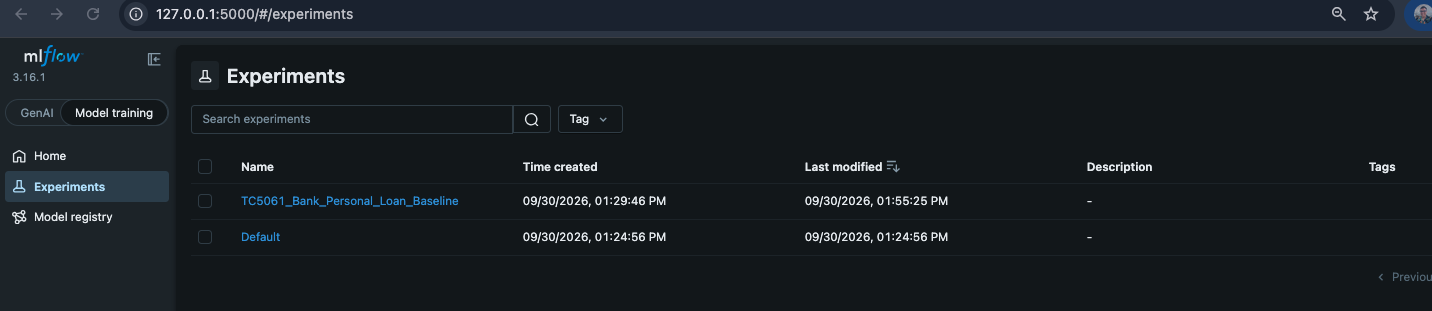


### Evidencia 2. Run del modelo baseline

**Figura 2. Run `logistic_regression_baseline` dentro del experimento.**  
La vista de Runs muestra la ejecución del baseline asociada al experimento, junto con su fuente y el modelo `baseline_model`. Esta evidencia permite verificar que el run quedó registrado dentro del experimento correspondiente.

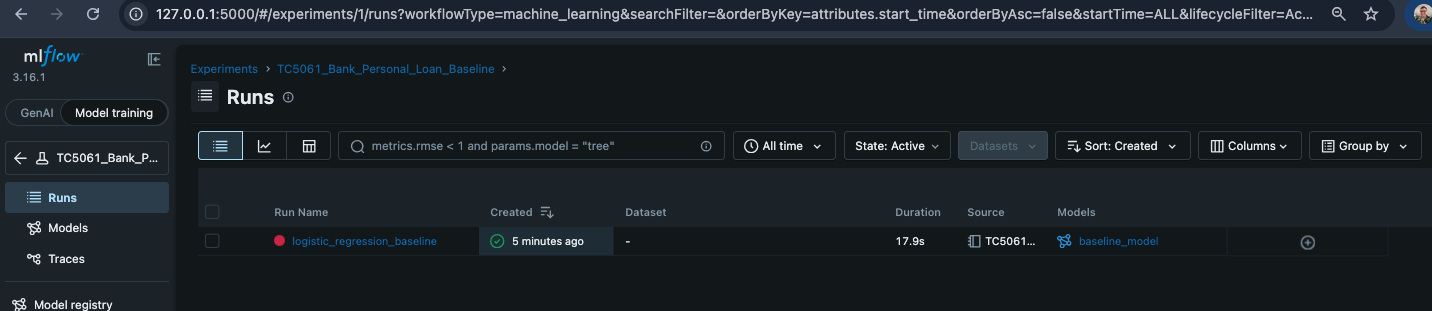


### Evidencia 3. Run registrado en MLflow

**Figura 3. Vista general del run `logistic_regression_baseline`.**  
La interfaz de MLflow muestra que el run finalizó con estado `Finished` y presenta de forma conjunta las métricas de evaluación, los parámetros de configuración, los tags del experimento y el modelo `baseline_model`. Esta captura constituye la evidencia principal del registro reproducible solicitado en la actividad.

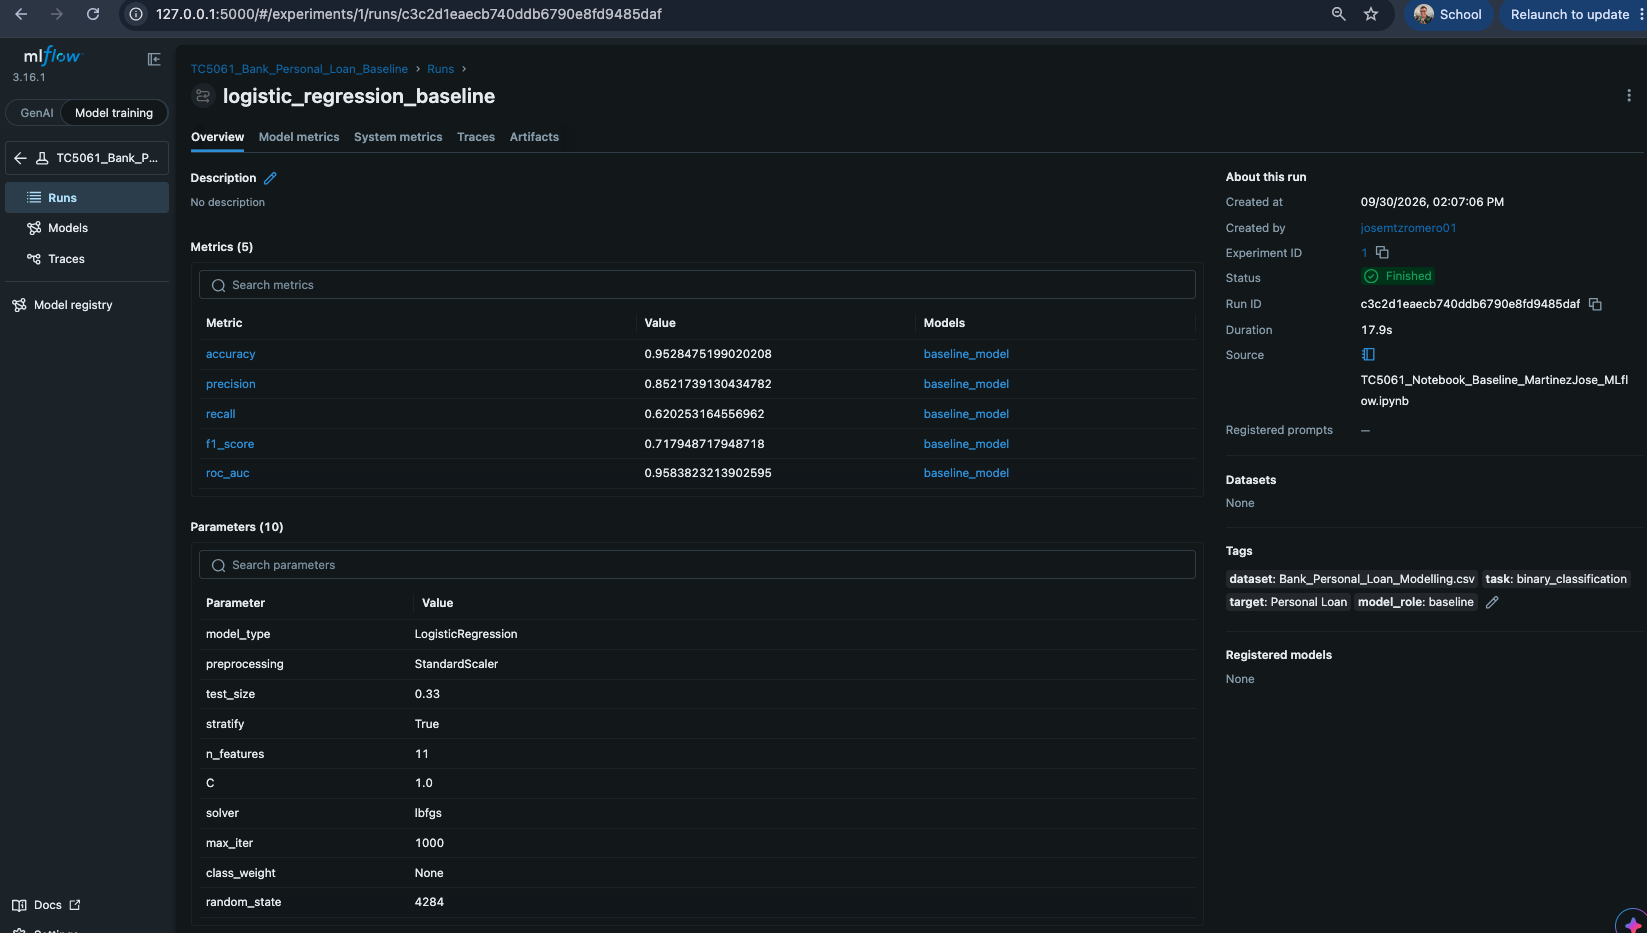


### Evidencia 4. Métricas registradas

**Figura 4. Métricas del modelo baseline registradas en MLflow.**  
Se observan las cinco métricas utilizadas para evaluar la Regresión Logística: `accuracy`, `precision`, `recall`, `f1_score` y `roc_auc`. Estas métricas coinciden con los resultados obtenidos previamente en la evaluación del modelo y permiten conservar un punto de referencia reproducible para comparaciones posteriores.

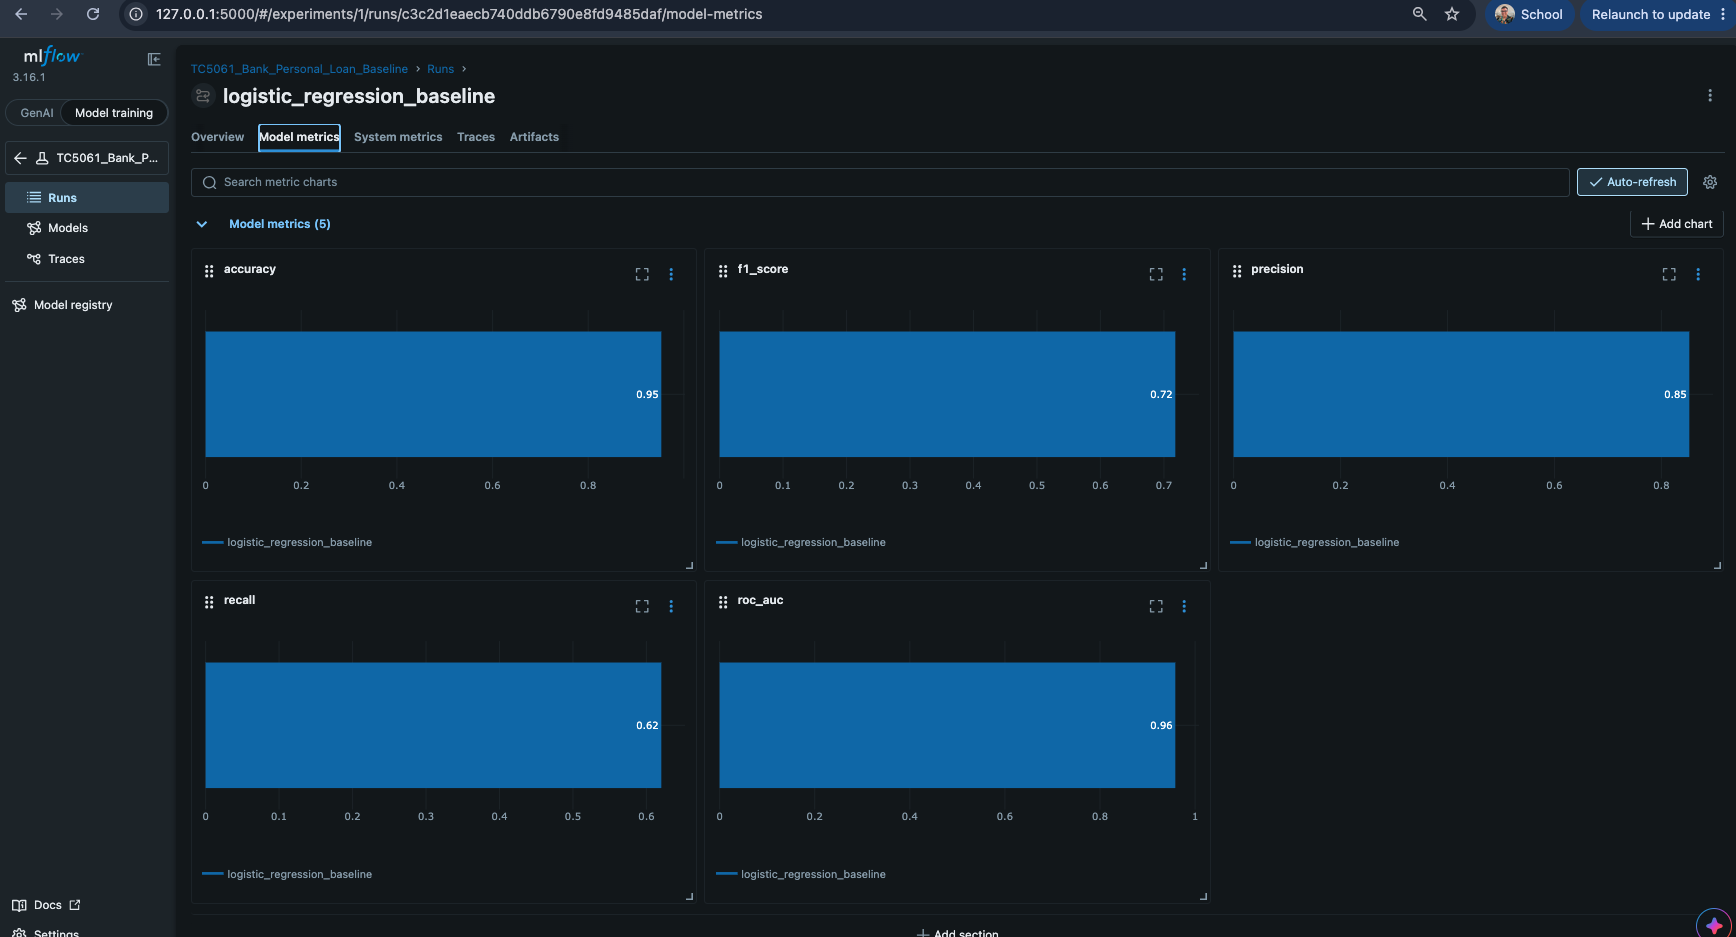


### Evidencia 5. Artefactos de evaluación del run

**Figura 5. Artefactos de evaluación registrados en el run de MLflow.**  
Además de parámetros y métricas, se registraron como artefactos del run el `classification_report.json`, la matriz de confusión y la curva ROC. Estos archivos conservan evidencia reproducible de la evaluación realizada sobre el modelo baseline y permiten revisar posteriormente los resultados sin volver a ejecutar el notebook.

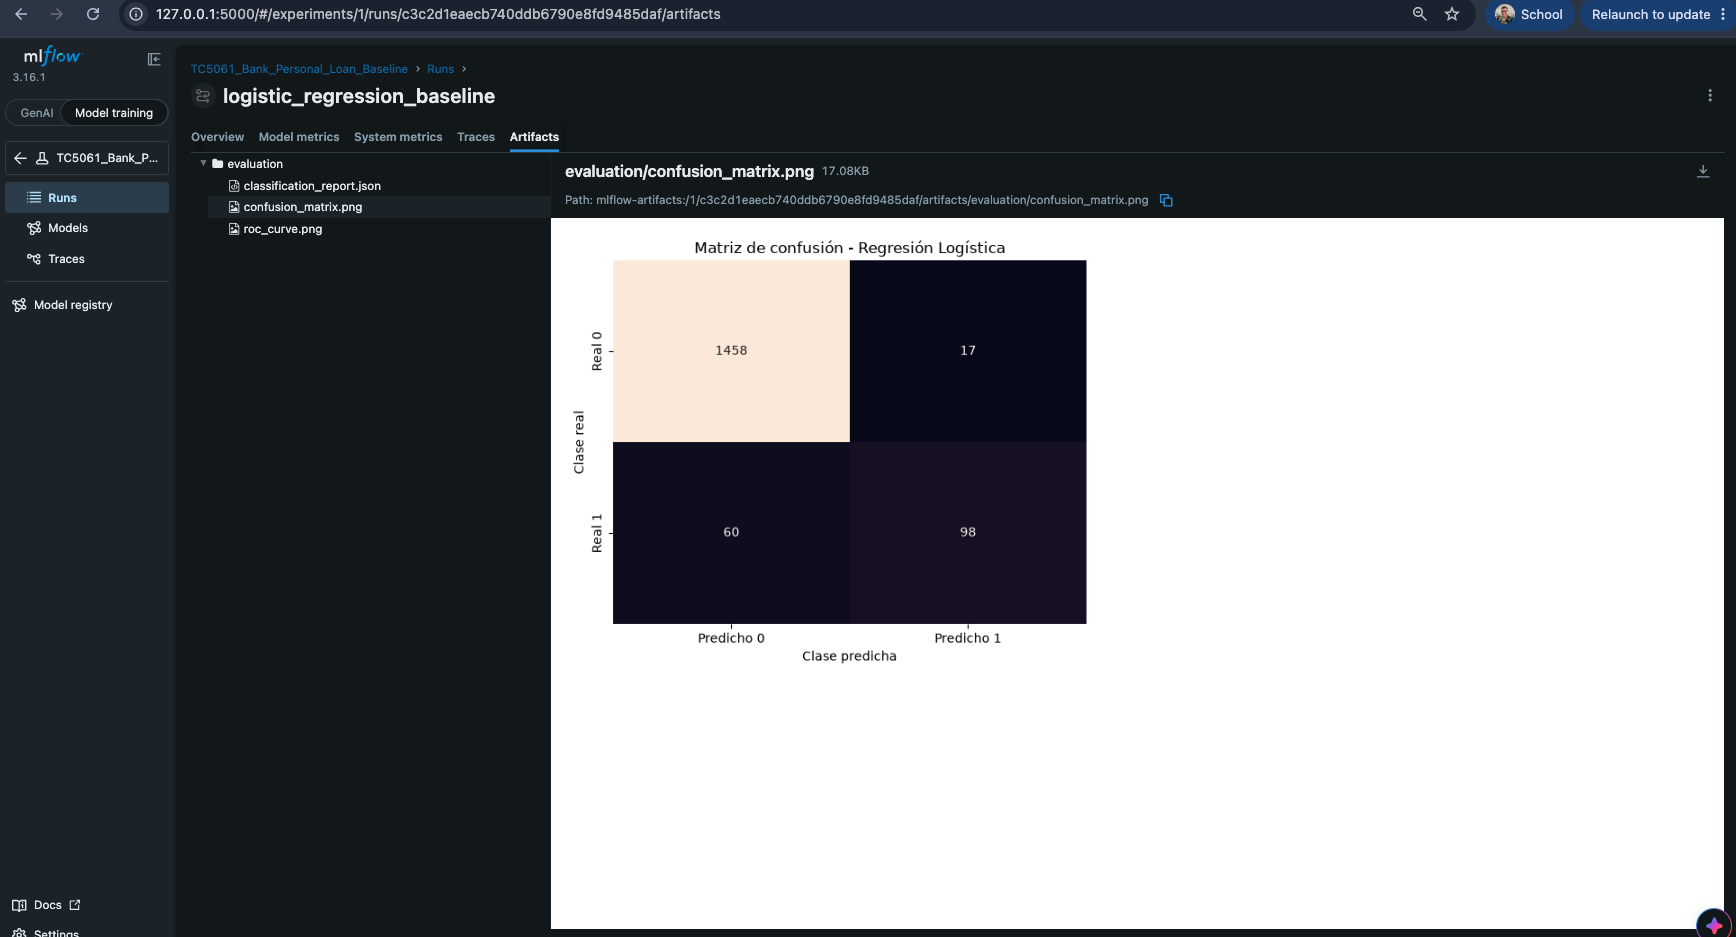


### Evidencia 6. Artefactos del modelo base

**Figura 6. Artefactos del modelo `baseline_model` almacenados por MLflow.**  
El pipeline entrenado fue registrado como **Logged Model** con el nombre `baseline_model`. MLflow almacenó los archivos necesarios para reproducir y cargar el modelo, entre ellos `MLmodel`, `model.skops`, `conda.yaml`, `python_env.yaml`, `requirements.txt`, `input_example.json` y `serving_input_example.json`. El archivo `MLmodel` también conserva la firma de entrada y salida del modelo.

Estos archivos corresponden directamente a los **artefactos del modelo base** solicitados de manera condicional en el Paso 6. El modelo aparece como **Not registered** porque no fue promovido al **Model Registry**; esto no representa un error ni un requisito pendiente, ya que la actividad solicita registrar el experimento en MLflow Tracking y, solo si aplica, los artefactos del modelo base.

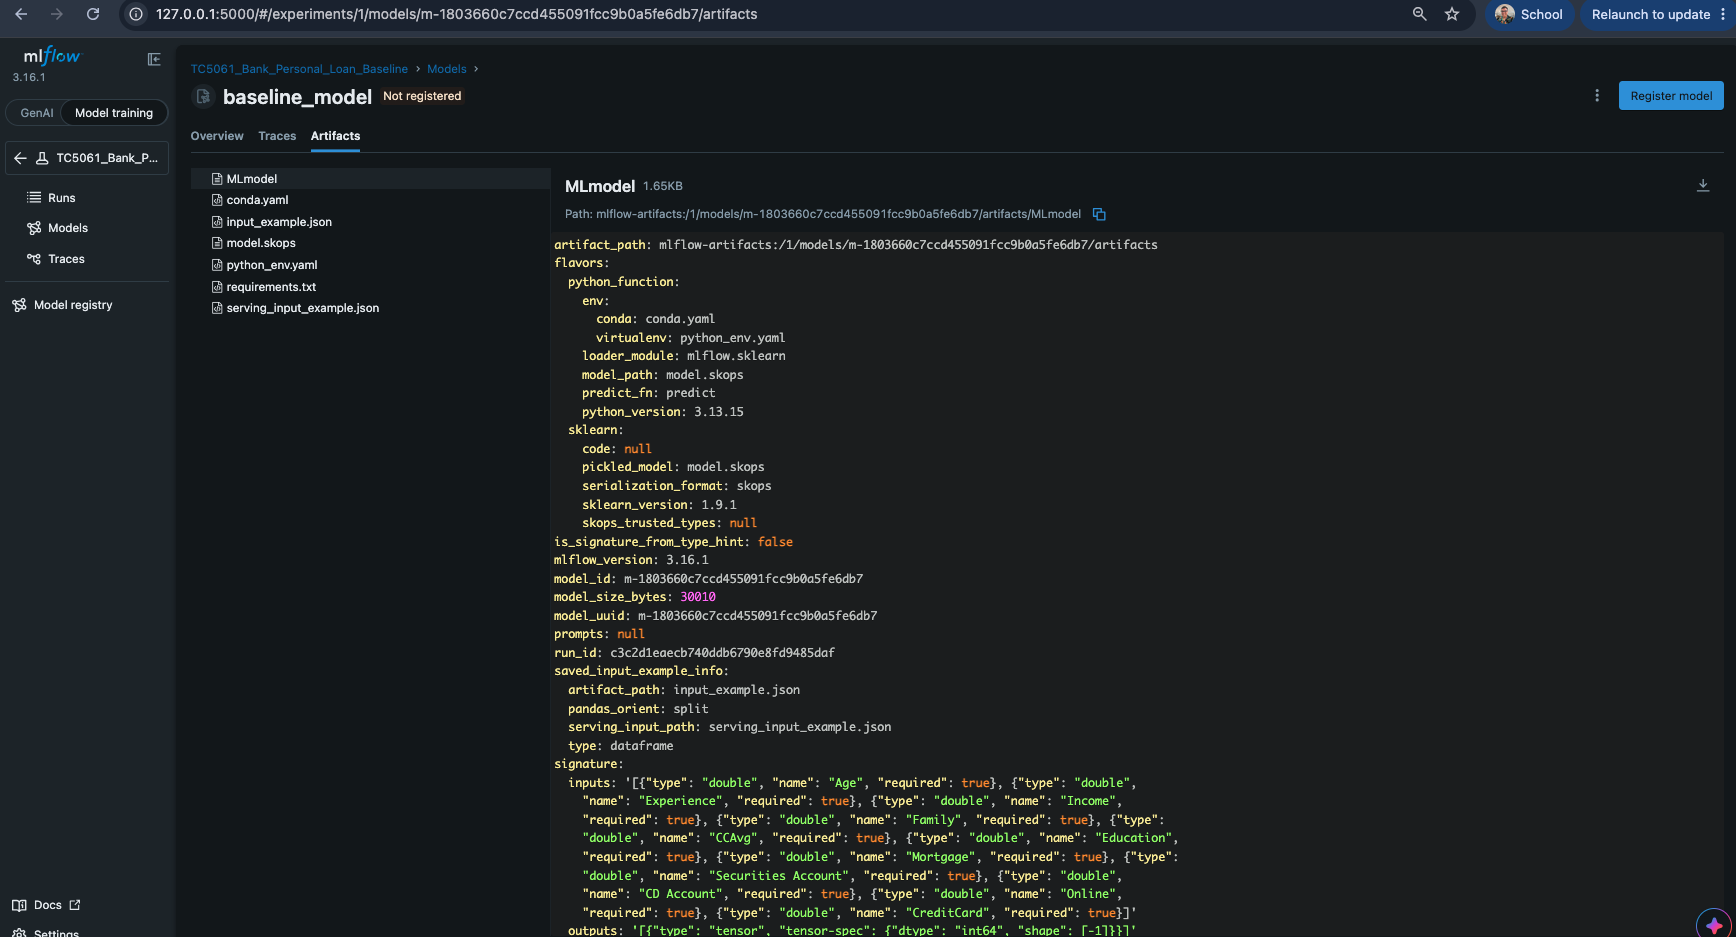


### Conclusión del registro en MLflow

El experimento baseline quedó registrado correctamente en MLflow Tracking con sus parámetros, métricas, tags y evidencias de evaluación. Además, el pipeline `baseline_model` fue almacenado como **Logged Model** junto con sus artefactos de reproducibilidad, como `MLmodel`, `model.skops`, archivos de dependencias, firma del modelo y ejemplos de entrada.

De esta manera se cubren dos tipos de evidencia complementaria: los **artefactos de evaluación del run** (`classification_report.json`, matriz de confusión y curva ROC) y los **artefactos del modelo base** generados por `mlflow.sklearn.log_model()`. No fue necesario registrar el modelo en **Model Registry**, ya que la actividad no solicita versionamiento, promoción o despliegue del modelo.


# 7. Reflexión final sobre MLOps

Esta actividad me ayudó a comprender mejor cómo un flujo de Machine Learning puede beneficiarse mediante el uso de prácticas de MLOps. Como se menciona en los temas de estudio de esta semana, para lograr un flujo de Machine Learning confiable es importante partir de un adecuado procesamiento y análisis de los datos, utilizando técnicas como EDA antes de realizar el entrenamiento y la validación del modelo. Aunque en este ejercicio se trabajó con un modelo baseline sencillo de Regresión Logística, considero que el flujo puede mejorarse automatizando varias etapas, como la validación de los datos, el entrenamiento, la evaluación del modelo y el registro de resultados en MLflow. También sería útil incorporar control de versiones para los datasets, los modelos y los parámetros utilizados, de manera que cada experimento pueda reproducirse fácilmente y compararse con ejecuciones anteriores.

Desde mi experiencia como DevOps, estos aprendizajes se relacionan mucho con conceptos que ya utilizo en integración y entrega continua. En proyectos de DevOps se crean pipelines de CI/CD para ejecutar pruebas automáticas, validar código, generar builds y desplegar aplicaciones en distintos ambientes. En MLOps encuentro una lógica similar en cuanto a automatización, trazabilidad y reproducibilidad, aunque las herramientas tienen funciones diferentes. Por ejemplo, Jenkins, GitHub Actions o Azure DevOps pueden utilizarse para automatizar pipelines, mientras que MLflow permite registrar experimentos, parámetros, métricas, modelos y artefactos asociados al ciclo de vida de Machine Learning.

Esta actividad también me ayudó a entender que MLOps no sustituye a DevOps, sino que amplía varias de sus prácticas al contexto de los modelos de Machine Learning. El uso de MLflow me pareció especialmente útil porque facilita el seguimiento de los experimentos y permite conservar evidencia de los resultados obtenidos, mejorando la trazabilidad y la reproducibilidad del proceso.

En mi área profesional, conocer con mayor detalle cómo funciona MLOps fortalece mis habilidades técnicas para participar en el desarrollo y mantenimiento de pipelines de Machine Learning. En un entorno real, un ingeniero MLOps puede colaborar con analistas y científicos de datos para automatizar el entrenamiento, despliegue, monitoreo y mantenimiento de modelos, de forma similar a como un ingeniero DevOps colabora con desarrolladores para automatizar el build y despliegue de aplicaciones. Por esta razón, considero que estos conocimientos complementan directamente mi experiencia actual y amplían mi perfil hacia proyectos relacionados con inteligencia artificial y Machine Learning.


# Referencias

OpenAI. (2026). *ChatGPT* [Modelo de lenguaje de gran escala]. https://chatgpt.com/

**Uso en esta actividad:** utilizado para generación y optimización de código y estructura del notebook.
